## 1.1 Setup Environment

Langkah persiapan environment sebelum mengerjakan UTS.

**1. Buat virtual environment** (di folder `Proyek Sains Data`)
```powershell
python -m venv myenv
```

**2. Aktifkan environment** (Windows PowerShell)
```powershell
myenv\Scripts\Activate.ps1
```
Jika berhasil, muncul `(myenv)` di depan prompt terminal.

**3. Verifikasi environment aktif**
```powershell
where.exe python
```
Baris paling atas harus mengarah ke `...\myenv\Scripts\python.exe`.

**4. Pindah ke folder UTS, lalu install dependensi**
```powershell
cd "Graf Sains Data\UTS"
python -m pip install -r requirements.txt
```
Atau tanpa pindah folder:
```powershell
python -m pip install -r "Graf Sains Data\UTS\requirements.txt"
```

**5. Cek paket terpasang**
```powershell
python -m pip list
```

**6. Pilih kernel notebook**
Klik *Select Kernel* di pojok kanan atas, lalu pilih `myenv`.

**7. Cek kernel dan versi library**
```python
import sys, neo4j
print(sys.executable)
print(neo4j.__version__)
```
Path harus ke `...\myenv\Scripts\python.exe`.

In [2]:
import sys, neo4j
print(sys.executable)
print(neo4j.__version__)

c:\Users\naufa\Downloads\Proyek Sains Data\myenv\Scripts\python.exe
6.4.1


### 1.2 Koneksi ke Neo4j

**Tujuan:** menyiapkan alamat dan kredensial untuk terhubung ke database Neo4j.

- `URI` : alamat server Neo4j (`bolt://localhost:7687`, artinya Neo4j lokal lewat port Bolt).
- `AUTH` : pasangan `(username, password)` untuk login.
- `GraphDatabase`, `RoutingControl` : class dari library `neo4j`. `RoutingControl` dipakai untuk menandai query sebagai baca (READ).

Sel ini belum terhubung ke database, hanya menyimpan konfigurasi.

In [8]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "uts12345")

### Tes Koneksi

**Tujuan:** memastikan Python benar-benar bisa terhubung ke Neo4j.

`driver.verify_connectivity()` mengecek server aktif dan kredensial benar. Jika berhasil tercetak "Terhubung ke Neo4j". Blok `with` menutup koneksi otomatis setelah selesai.

In [10]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Terhubung ke Neo4j")

Terhubung ke Neo4j


### Fungsi `add_friend`

**Tujuan:** membuat dua node `Person` dan relasi `KNOWS` di antara keduanya.

- `MERGE (a:Person {name: $name})` : cari node Person dengan nama tersebut, jika belum ada maka dibuat.
- `MERGE (friend:Person {name: $friend_name})` : sama, untuk teman.
- `MERGE (a)-[:KNOWS]->(friend)` : buat relasi berarah dari `a` ke `friend`.
- `$name` dan `$friend_name` adalah parameter yang nilainya diisi dari argumen Python.
- `database_="neo4j"` : menentukan database tujuan.

Karena memakai `MERGE`, menjalankan fungsi berulang kali tidak membuat data ganda.

In [11]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

### Fungsi `print_friends`

**Tujuan:** menampilkan semua teman dari seseorang.

- `MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name` : cari semua node yang dituju relasi `KNOWS` dari orang bernama `$name`.
- `RETURN friend.name ORDER BY friend.name` : ambil nama teman, diurutkan alfabet.
- `routing_=RoutingControl.READ` : menandai query hanya membaca data.
- Hasil (`records`) di-loop lalu dicetak satu per satu.

In [12]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

### Menjalankan Tutorial

**Tujuan:** membuat graf pertemanan lalu menampilkannya.

Arthur dihubungkan ke Guinevere, Lancelot, dan Merlin lewat `add_friend`, kemudian `print_friends` menampilkan teman Arthur.

**Output:** Guinevere, Lancelot, Merlin (urut alfabet).

**Hasil graf:** directed graph berbentuk bintang, dengan Arthur di tengah dan relasi `KNOWS` mengarah ke tiga temannya.

In [13]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


In [14]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Gon", "Killua")
    add_friend(driver, "Gon", "Kurapika")
    add_friend(driver, "Gon", "Leorio")
    print_friends(driver, "Gon")

Killua
Kurapika
Leorio


**Output:** Killua, Kurapika, Leorio (urut alfabet).

**Hasil graf:** directed graph berbentuk bintang, dengan Gon di tengah dan relasi `KNOWS` mengarah ke tiga temannya.

### Jawaban Pertanyaan Pendahuluan (Checkpoint)

**1. Apa nama database yang digunakan pada tutorial ini?**

`neo4j` (database default). Terlihat dari `database_="neo4j"` pada `add_friend` dan `print_friends`. Terbukti lewat `SHOW DATABASES`: hanya ada `neo4j` (data Gon, Killua, Kurapika, Leorio) dan `system` (administrasi).

**2. Akses lain untuk mengakses database dalam 1 instance**

- Parameter `database_="namadb"` pada `driver.execute_query(...)`, atau `driver.session(database="namadb")`.
- Klausa Cypher `USE namadb`.
- Perintah `:use namadb` di Neo4j Browser.
- DDL di database `system`: `CREATE DATABASE`, `SHOW DATABASES`, `START DATABASE`, `STOP DATABASE`, `DROP DATABASE`.

Catatan: multi-database hanya di Enterprise Edition.

**3. Jenis graf pertemanan yang dibuat**

*Directed graph* dengan satu tipe node (`Person`) dan satu tipe relasi (`KNOWS`). Gon menjadi pusat yang mengarah ke Killua, Kurapika, dan Leorio sehingga berbentuk *star*. Graf ini *unweighted* dan *simple* (tanpa relasi ganda karena memakai `MERGE`).

In [17]:
#DELETE
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query(
        "MATCH (p:Person) WHERE p.name IN $names DETACH DELETE p",
        names=["Arthur", "Guinevere", "Lancelot", "Merlin"],
        database_="neo4j",
    )

### Visualisasi Graf Pertemanan

**Tujuan:** menampilkan graf `Person -[:KNOWS]-> Person` dari Neo4j sebagai directed graph di notebook.

Data diambil dengan Cypher, dimasukkan ke `networkx.DiGraph` (graf berarah), lalu digambar dengan `matplotlib`.

In [18]:
import networkx as nx
import matplotlib.pyplot as plt

URI = "bolt://localhost:7687"
AUTH = ("neo4j", "uts12345")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(b:Person) RETURN a.name AS dari, b.name AS ke",
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

edges = [(r["dari"], r["ke"]) for r in records]
print(edges)

[('Gon', 'Killua'), ('Gon', 'Kurapika'), ('Gon', 'Leorio')]


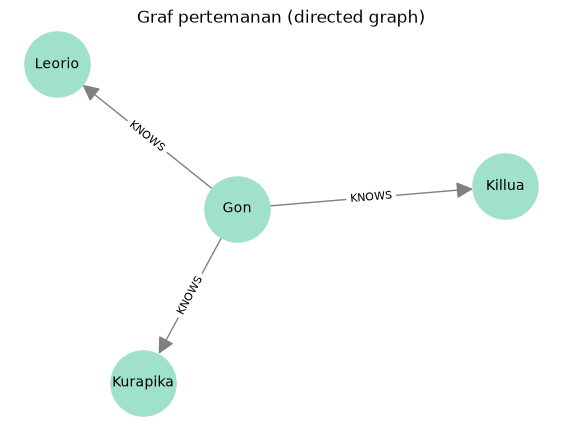

In [19]:
G = nx.DiGraph()
G.add_edges_from(edges)

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(7, 5))
nx.draw_networkx_nodes(G, pos, node_color="#9FE1CB", node_size=2200)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edges(
    G, pos, arrowstyle="-|>", arrowsize=25,
    node_size=2200, edge_color="gray",
)
nx.draw_networkx_edge_labels(G, pos, edge_labels={e: "KNOWS" for e in G.edges()}, font_size=8)

plt.title("Graf pertemanan (directed graph)")
plt.axis("off")
plt.show()

1.3

In [20]:
import pandas as pd

df = pd.read_csv("data/events.csv")
print(df.shape)
df.head()

(2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


### 1.3 Impor Data RetailRocket

**Fitur pada events.csv:**
- `timestamp` : waktu kejadian, Unix epoch dalam milidetik.
- `visitorid` : ID unik pengunjung (node `Visitor`).
- `event` : jenis interaksi: `view`, `addtocart`, `transaction`.
- `itemid` : ID unik produk (node `Item`).
- `transactionid` : ID transaksi, hanya terisi saat `event = transaction`.

**Model graf:** `(Visitor)-[:VIEWED | :ADDED_TO_CART | :BOUGHT]->(Item)`

In [21]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["tanggal"] = pd.to_datetime(df["timestamp"], unit="ms")

print(df.shape)
print(df["tanggal"].min(), "->", df["tanggal"].max())
print(df["event"].value_counts())
df.head()

(2756101, 6)
2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,tanggal
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


In [22]:
import os, sys
from neo4j import GraphDatabase

BOLT = "bolt://localhost:7687"
USER = "neo4j"
PASSWORD = "uts12345"
SOURCE = "data"

csv_file_path = os.path.join(SOURCE, "events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

try:
    driver = GraphDatabase.driver(BOLT, auth=(USER, PASSWORD))
    driver.verify_connectivity()
    print("Terhubung ke Neo4j")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

Terhubung ke Neo4j


**Koneksi ke Neo4j:** mengecek `events.csv` ada, lalu membuat driver dan memverifikasi koneksi dengan `verify_connectivity()`. Argparse pada contoh soal diganti variabel biasa karena dijalankan di notebook, bukan terminal.

In [23]:
def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT visitor_id IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT item_id IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )


def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [24]:
from tqdm.auto import tqdm

batch_size = 10000

# hitung total baris (dikurangi 1 untuk header)
with open(csv_file_path, encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1
total_chunks = (total_rows // batch_size) + 1

with driver.session(database="neo4j") as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # membersihkan null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

c:\Users\naufa\Downloads\Proyek Sains Data\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [03:44<00:00,  1.23it/s]

Proses impor berhasil.


In [25]:
driver = GraphDatabase.driver(BOLT, auth=(USER, PASSWORD))
records, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n)[0] AS tipe, count(*) AS jumlah",
    database_="neo4j",
)
for r in records:
    print(r["tipe"], r["jumlah"])

records, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah",
    database_="neo4j",
)
for r in records:
    print(r["relasi"], r["jumlah"])

Visitor 1407580
Person 4
Item 235061
VIEWED 2664312
KNOWS 3
ADDED_TO_CART 69332
BOUGHT 22457


**Constraint dan query impor:** `create_constraints` membuat constraint unik pada `visitorId` dan `itemId` agar `MERGE` efisien. `import_batch` memasukkan satu batch baris: `MERGE` membuat node `Visitor` dan `Item`, lalu `CALL { UNION ALL }` membuat relasi `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT` sesuai kolom `event`.

**Impor batch:** CSV dibaca per potongan (`chunksize`) agar hemat memori, kolom `transactionid` dibersihkan dari NaN, lalu tiap batch ditulis ke Neo4j dengan `execute_write`.

In [26]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["tanggal"] = pd.to_datetime(df["timestamp"], unit="ms")

# P1 = training, P2 = testing (batas akhir inklusif: sampai 23:59:59 hari terakhir)
p1_start, p1_end = "2015-05-03", "2015-07-04"   # 03/05/2015 s/d 03/07/2015
p2_start, p2_end = "2015-07-12", "2015-07-28"   # 12/07/2015 s/d 27/07/2015

df_p1 = df[(df["tanggal"] >= p1_start) & (df["tanggal"] < p1_end)]
df_p2 = df[(df["tanggal"] >= p2_start) & (df["tanggal"] < p2_end)]

print("P1:", df_p1.shape, df_p1["tanggal"].min(), "->", df_p1["tanggal"].max())
print("P2:", df_p2.shape, df_p2["tanggal"].min(), "->", df_p2["tanggal"].max())

P1: (1264004, 6) 2015-05-03 03:00:04.384000 -> 2015-07-03 23:59:57.768000
P2: (377369, 6) 2015-07-12 00:00:02.350000 -> 2015-07-27 23:59:58.145000


In [27]:
df_p1.drop(columns="tanggal").to_csv("data/events_p1.csv", index=False)
df_p2.drop(columns="tanggal").to_csv("data/events_p2.csv", index=False)
print("Tersimpan: data/events_p1.csv dan data/events_p2.csv")

Tersimpan: data/events_p1.csv dan data/events_p2.csv


In [28]:
for nama, d in [("P1", df_p1), ("P2", df_p2)]:
    print(f"\n{nama}")
    print("Baris        :", len(d))
    print("Visitor unik :", d["visitorid"].nunique())
    print("Item unik    :", d["itemid"].nunique())
    print(d["event"].value_counts().to_string())

# visitor yang muncul di P1 dan P2 (calon user buat soal 2.2)
irisan = set(df_p1["visitorid"]) & set(df_p2["visitorid"])
print("\nVisitor ada di P1 dan P2:", len(irisan))


P1
Baris        : 1264004
Visitor unik : 637379
Item unik    : 166996
event
view           1222938
addtocart        30907
transaction      10159

P2
Baris        : 377369
Visitor unik : 210772
Item unik    : 90291
event
view           365392
addtocart        9003
transaction      2974

Visitor ada di P1 dan P2: 11710


### Kesimpulan No. 1 dan 2

Filter periode berhasil diterapkan pada `timestamp` dan hasilnya disimpan ke `events_p1.csv` dan `events_p2.csv`.

| | P1 (training) | P2 (testing) |
|---|---|---|
| Baris | 1.264.004 (45,9% dari total) | 377.369 (13,7% dari total) |
| Visitor unik | 637.379 | 210.772 |
| Item unik | 166.996 | 90.291 |
| `view` / `addtocart` / `transaction` | 96,75% / 2,45% / 0,80% | 96,83% / 2,39% / 0,79% |

1. **Filter benar:** rentang waktu P1 berakhir 03/07/2015 23:59:57 dan P2 mulai 12/07/2015 00:00:02, tidak ada tumpang tindih, dan jumlah baris file CSV sama dengan hasil filter.
2. **Kedua fold konsisten:** proporsi `view`, `addtocart`, dan `transaction` hampir identik, sehingga P2 layak menjadi data uji bagi model yang dibangun dari P1.
3. **Irisan user kecil:** hanya 11.710 visitor muncul di kedua fold (1,84% dari visitor P1 dan 5,56% dari visitor P2). Ini membatasi evaluasi rekomendasi di 2.2, karena hanya user yang ada di P1 dan P2 yang punya ground truth.
4. **Pembagian waktu menjaga validitas evaluasi:** P2 sepenuhnya setelah P1 dengan jeda 8 hari, sehingga tidak ada kebocoran data dari masa depan ke training.

## 2.1 Wrangling dan EDA

### Filter periode waktu

Data interaksi dibagi menjadi dua fold berdasarkan `timestamp`:

| Fold | Periode | Fungsi |
|---|---|---|
| P1 (training) | 03/05/2015 - 03/07/2015 | membangun graf, similarity, dan rekomendasi |
| P2 (testing) | 12/07/2015 - 27/07/2015 | ground truth untuk evaluasi Hit@5 dan NDCG@5 |

Kolom `timestamp` berupa Unix epoch dalam milidetik, sehingga dikonversi dengan `pd.to_datetime(..., unit="ms")` sebelum difilter. Batas akhir dibuat inklusif dengan memakai `<` terhadap hari berikutnya. Terdapat jeda 04/07 - 11/07 antara kedua fold untuk menghindari kebocoran data. Hasil filter disimpan ke `events_p1.csv` dan `events_p2.csv`.

## 2.1 Wrangling dan EDA
  1. Periode waktu          -> markdown + (filter, sudah)
  2. Simpan CSV             -> markdown + kode (sudah)
  3. Komposisi subgraph     -> markdown + impor ulang + query Cypher
  4. VSM user               -> markdown + kode + plot networkx
  5. VSM item               -> markdown + kode + plot networkx
  6. Proyeksi mana lebih baik -> markdown (analisis dari no. 4 dan 5)
  7. Similarity             -> markdown + kode + Cypher (a) top-5, (b) tulis balik
  8. Sebelum dan sesudah similarity -> markdown + Cypher + screenshot graf

## 2.2 Analytics
  1. User acak, KNN k=5, 3 item iklan -> markdown + kode
  2. Hit@5 dan NDCG@5                 -> markdown + kode

**Soal 2.1 no. 1 dan 2: tentuin periode, filter, simpan ke CSV**

***Sel 1: hapus graf lama***

In [30]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(BOLT, auth=(USER, PASSWORD))

with driver.session(database="neo4j") as session:
    # 1) hapus relasi per 10.000
    session.run(
        "MATCH ()-[r]->() "
        "CALL { WITH r DELETE r } IN TRANSACTIONS OF 10000 ROWS"
    ).consume()
    # 2) lalu hapus node per 10.000
    session.run(
        "MATCH (n) "
        "CALL { WITH n DELETE n } IN TRANSACTIONS OF 10000 ROWS"
    ).consume()

print("Graf lama dihapus")

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (r) { ... }', position=<SummaryInputPosition line=1, column=18, offset=17>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 17, 'line': 1, 'column': 18}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH ()-[r]->() CALL { WITH r DELETE r } IN TRANSACTIONS OF 10000 ROWS'
Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=1, column=11, offset=10>, 

Graf lama dihapus


In [31]:
records, _, _ = driver.execute_query(
    "MATCH (n) RETURN count(n) AS jumlah", database_="neo4j"
)
print(records[0]["jumlah"])

0


***Sel 2: impor P1***

In [32]:
from tqdm.auto import tqdm

csv_p1 = "data/events_p1.csv"
batch_size = 5000
total_rows = 1264004
total_chunks = (total_rows // batch_size) + 1

with driver.session(database="neo4j") as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_p1, chunksize=batch_size)

    for chunk in tqdm(chunks, total=total_chunks, desc="Impor P1"):
        chunk["transactionid"] = (
            chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        )
        session.execute_write(import_batch, chunk.to_dict(orient="records"))

print("Impor P1 selesai")

Impor P1: 100%|██████████| 253/253 [01:44<00:00,  2.42it/s]

Impor P1 selesai


***Sel 3: cek hasil***

In [33]:
records, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n)[0] AS tipe, count(*) AS jumlah",
    database_="neo4j",
)
for r in records:
    print(r["tipe"], r["jumlah"])

records, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah",
    database_="neo4j",
)
for r in records:
    print(r["relasi"], r["jumlah"])

Visitor 637379
Item 166996
VIEWED 1222938
ADDED_TO_CART 30907
BOUGHT 10159


**Soal 2.1 no. 3: query komposisi subgraph (jenis simpul dan jumlahnya) lewat Python API, plus penjelasan Cypher-nya.**

***Sel 1: komposisi simpul (node)***

In [34]:
import pandas as pd

q_node = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC
"""

records, _, _ = driver.execute_query(q_node, database_="neo4j")
df_node = pd.DataFrame([r.data() for r in records])
df_node

,jenis_simpul,jumlah
0,Visitor,637379
1,Item,166996


***Sel 2: komposisi relasi (edge), pelengkap***

In [35]:
q_rel = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(*) AS jumlah
ORDER BY jumlah DESC
"""

records, _, _ = driver.execute_query(q_rel, database_="neo4j")
df_rel = pd.DataFrame([r.data() for r in records])
df_rel

,jenis_relasi,jumlah
0,VIEWED,1222938
1,ADDED_TO_CART,30907
2,BOUGHT,10159


***Sel 3: pola graf, biar kelihatan Visitor nyambung ke Item lewat relasi apa***

In [36]:
q_pola = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN labels(v)[0] AS dari, type(r) AS relasi, labels(i)[0] AS ke, count(*) AS jumlah
ORDER BY jumlah DESC
"""

records, _, _ = driver.execute_query(q_pola, database_="neo4j")
pd.DataFrame([r.data() for r in records])

,dari,relasi,ke,jumlah
0,Visitor,VIEWED,Item,1222938
1,Visitor,ADDED_TO_CART,Item,30907
2,Visitor,BOUGHT,Item,10159


In [37]:
q_unik = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN type(r) AS relasi,
       count(*)              AS jumlah_kejadian,
       count(DISTINCT v)     AS visitor_unik,
       count(DISTINCT i)     AS item_unik
ORDER BY jumlah_kejadian DESC
"""

records, _, _ = driver.execute_query(q_unik, database_="neo4j")
pd.DataFrame([r.data() for r in records])

,relasi,jumlah_kejadian,visitor_unik,item_unik
0,VIEWED,1222938,636069,166828
1,ADDED_TO_CART,30907,17156,13912
2,BOUGHT,10159,5489,6511


### 2.1 No. 3 - Kesimpulan Komposisi Subgraph

**Nama:** r1th404 | **Fold:** 
**P1 (training):** 03/05/2015 - 03/07/2015

Subgraph dari data P1 dianalisis dengan menghitung jumlah kejadian, visitor unik, dan item unik pada tiap jenis relasi.

| Relasi | Jumlah kejadian | Visitor unik | Item unik |
|---|---|---|---|
| VIEWED | 1.222.938 | 636.069 | 166.828 |
| ADDED_TO_CART | 30.907 | 17.156 | 13.912 |
| BOUGHT | 10.159 | 5.489 | 6.511 |

Total simpul: 637.379 `Visitor` dan 166.996 `Item`.

**Kesimpulan:**

1. **Graf bersifat bipartit.** Hanya ada dua jenis simpul (`Visitor` dan `Item`), dan semua relasi mengarah dari `Visitor` ke `Item`. Tidak ada relasi Visitor-Visitor maupun Item-Item, sehingga kemiripan antar user atau antar item harus diperoleh lewat proyeksi.

2. **Aktivitas didominasi melihat produk.** `VIEWED` mencakup 1.222.938 dari 1.264.004 kejadian (96,7%), sedangkan `ADDED_TO_CART` 2,4% dan `BOUGHT` 0,8%. Pola ini menunjukkan corong (funnel) e-commerce: banyak yang melihat, sedikit yang membeli.

3. **Hampir semua visitor dan item pernah di-view.** Visitor unik `VIEWED` sebanyak 636.069 dari 637.379 (99,8%), dan item unik `VIEWED` sebanyak 166.828 dari 166.996 (99,9%). Artinya `VIEWED` hampir mencakup seluruh simpul graf.

4. **Hanya sebagian kecil visitor yang membeli.** Visitor yang melakukan `BOUGHT` hanya 5.489 (0,86% dari seluruh visitor), dan yang memasukkan ke keranjang 17.156 (2,69%). Dari sisi item, hanya 6.511 item (3,90%) yang pernah dibeli dan 13.912 item (8,33%) yang pernah masuk keranjang. Sinyal pembelian sangat jarang (sparse).

5. **Visitor umumnya berinteraksi sedikit.** Rata-rata hanya 1,92 kejadian `VIEWED` per visitor unik (1.222.938 / 636.069). Matriks user-item yang terbentuk akan sangat jarang (sparse), sehingga representasi VSM memerlukan matriks sparse.

**Implikasi untuk analisis berikutnya:** karena `VIEWED` adalah relasi paling lengkap (mencakup hampir semua visitor dan item), relasi ini cocok sebagai dasar pembentukan matriks user-item pada VSM. `BOUGHT` dan `ADDED_TO_CART` terlalu sedikit untuk berdiri sendiri, tetapi bisa dipakai sebagai sinyal yang lebih kuat.

**Soal 2.1 no. 4: VSM sisi User**

Tiap user dijadiin satu vektor, dimensinya = semua item. Baris matriks = user, kolom = item, isi sel = seberapa kuat interaksinya.

***Sel 1: bangun matriks user × item (sparse)***

In [38]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

df_p1 = pd.read_csv("data/events_p1.csv")

# bobot tiap jenis interaksi
bobot = {"view": 1, "addtocart": 3, "transaction": 5}
df_p1["bobot"] = df_p1["event"].map(bobot)

# jumlahkan bobot per pasangan (user, item)
agg = df_p1.groupby(["visitorid", "itemid"], as_index=False)["bobot"].sum()

user_cat = agg["visitorid"].astype("category")
item_cat = agg["itemid"].astype("category")
user_labels = user_cat.cat.categories   # baris ke-i = visitorid ini
item_labels = item_cat.cat.categories   # kolom ke-j = itemid ini

n_user, n_item = len(user_labels), len(item_labels)
X_user = csr_matrix(
    (agg["bobot"].values, (user_cat.cat.codes, item_cat.cat.codes)),
    shape=(n_user, n_item),
)
print("Shape matriks :", X_user.shape)

Shape matriks : (637379, 166996)


***Sel 2: karakteristik matriks***

In [39]:
nnz = X_user.nnz
total_sel = n_user * n_item

print("Dimensi vektor user (jumlah item):", n_item)
print("Jumlah user (baris)              :", n_user)
print("Sel terisi (non-zero)            :", nnz)
print(f"Density                          : {nnz / total_sel:.6%}")
print(f"Sparsity                         : {1 - nnz / total_sel:.4%}")
print(f"Memori jika dense (float64)      : {total_sel * 8 / 1e9:,.0f} GB")
print(f"Memori sparse (CSR)              : {(X_user.data.nbytes + X_user.indices.nbytes + X_user.indptr.nbytes) / 1e6:,.1f} MB")

per_user = np.diff(X_user.indptr)   # jumlah item berbeda per user
print("\nItem berbeda per user:")
print(pd.Series(per_user).describe())
print(f"User dengan hanya 1 item: {(per_user == 1).mean():.2%}")

Dimensi vektor user (jumlah item): 166996
Jumlah user (baris)              : 637379
Sel terisi (non-zero)            : 974310
Density                          : 0.000915%
Sparsity                         : 99.9991%
Memori jika dense (float64)      : 852 GB
Memori sparse (CSR)              : 14.2 MB

Item berbeda per user:
count    637379.000000
mean          1.528620
std           5.793141
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        1314.000000
dtype: float64
User dengan hanya 1 item: 79.51%


***Sel 3: plot networkx (sampel kecil)***

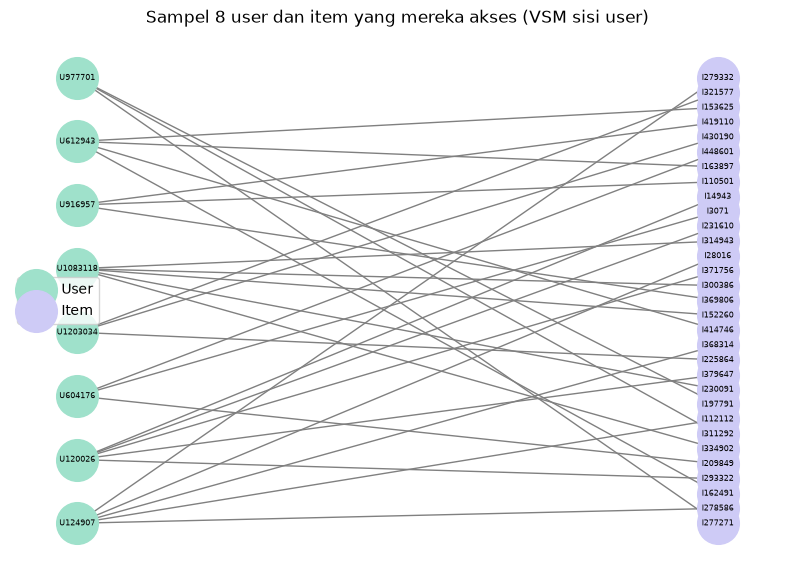

In [40]:
import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
kandidat = np.where((per_user >= 3) & (per_user <= 6))[0]
sampel = rng.choice(kandidat, size=8, replace=False)

G = nx.Graph()
user_nodes, item_nodes = [], []
for u in sampel:
    uname = f"U{user_labels[u]}"
    user_nodes.append(uname)
    kolom = X_user.indices[X_user.indptr[u]:X_user.indptr[u + 1]]
    bobot_u = X_user.data[X_user.indptr[u]:X_user.indptr[u + 1]]
    for c, w in zip(kolom, bobot_u):
        iname = f"I{item_labels[c]}"
        G.add_edge(uname, iname, weight=w)
        if iname not in item_nodes:
            item_nodes.append(iname)

pos = nx.bipartite_layout(G, user_nodes)
plt.figure(figsize=(10, 7))
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="#9FE1CB", node_size=900, label="User")
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="#CECBF6", node_size=900, label="Item")
nx.draw_networkx_edges(G, pos, edge_color="gray")
nx.draw_networkx_labels(G, pos, font_size=6)
plt.title("Sampel 8 user dan item yang mereka akses (VSM sisi user)")
plt.legend(scatterpoints=1)
plt.axis("off")
plt.show()

Kandidat user : 5281
User terpilih : 123341
Jumlah item   : 5 dari 166996 dimensi


,itemid,bobot
0,385862,5
1,329857,2
2,411650,2
3,451027,2
4,44023,1


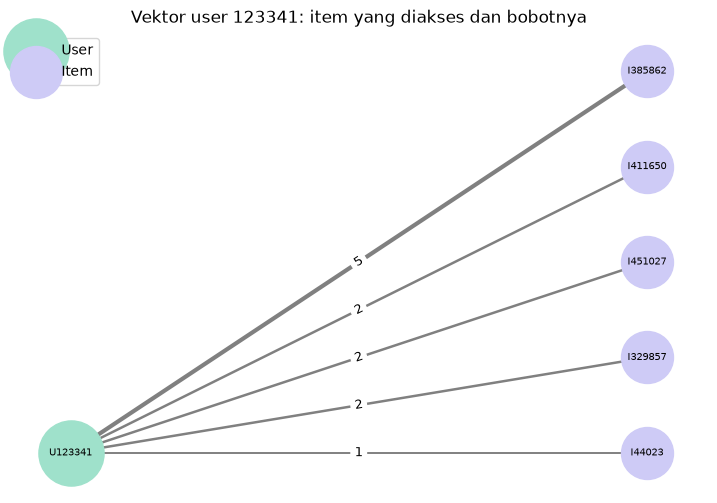

In [64]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# user acak (reproducible): 5-8 item, dan ada interaksi addtocart/transaction (bobot >= 3)
bobot_maks = X_user.max(axis=1).toarray().ravel()
kandidat = np.where((per_user >= 5) & (per_user <= 8) & (bobot_maks >= 3))[0]

rng = np.random.default_rng(42)
u = int(rng.choice(kandidat))
uname = f"U{user_labels[u]}"

# vektor user: item yang diakses beserta bobotnya
s, e = X_user.indptr[u], X_user.indptr[u + 1]
kolom = X_user.indices[s:e]
bobot = X_user.data[s:e]

df_vektor = pd.DataFrame({
    "itemid": item_labels[kolom],
    "bobot": bobot,
}).sort_values(["bobot", "itemid"], ascending=[False, True]).reset_index(drop=True)

print("Kandidat user :", len(kandidat))
print("User terpilih :", user_labels[u])
print("Jumlah item   :", len(df_vektor), "dari", n_item, "dimensi")
display(df_vektor)

# graf: 1 user -> item yang diaksesnya
G = nx.Graph()
item_nodes = []
for _, r in df_vektor.iterrows():
    iname = f"I{int(r['itemid'])}"
    G.add_edge(uname, iname, weight=int(r["bobot"]))
    item_nodes.append(iname)

pos = nx.bipartite_layout(G, [uname])
lebar = [1 + 0.4 * G[a][b]["weight"] for a, b in G.edges()]

plt.figure(figsize=(9, 6))
nx.draw_networkx_nodes(G, pos, nodelist=[uname], node_color="#9FE1CB", node_size=2200, label="User")
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="#CECBF6", node_size=1400, label="Item")
nx.draw_networkx_edges(G, pos, edge_color="gray", width=lebar)
nx.draw_networkx_labels(G, pos, font_size=7)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=9)
plt.title(f"Vektor user {user_labels[u]}: item yang diakses dan bobotnya")
plt.legend(scatterpoints=1)
plt.axis("off")
plt.show()

### Plot networkx: Contoh Vektor Satu User

Plot ini menunjukkan **satu contoh user** (`visitorid` = 123341), dipilih acak dengan `np.random.default_rng(42)` dari user yang punya 5 sampai 8 item dan minimal satu bobot ≥ 3. Tujuannya untuk memperlihatkan bentuk vektor user pada matriks user × item.

**Cara membaca plot:**
- Simpul hijau di kiri adalah user, simpul ungu di kanan adalah item yang pernah diaksesnya.
- Garis menghubungkan user ke item yang diakses, dan **angka di garis adalah bobot interaksi** (isi sel matriks). Garis yang lebih tebal berarti interaksinya lebih kuat.
- Item yang tidak pernah diakses user tidak digambar karena nilainya 0.

**Vektor user 123341:**

| Item | Bobot |
|---|---|
| 385862 | 5 |
| 329857 | 2 |
| 411650 | 2 |
| 451027 | 2 |
| 44023 | 1 |

**Karakteristik vektor:**

| Karakteristik | Nilai |
|---|---|
| Dimensi vektor | 166.996 (jumlah item) |
| Dimensi terisi (non-zero) | 5 |
| Density vektor | 0,0030% (5 / 166.996) |
| Total bobot | 12 |
| Panjang vektor (norma L2) | √(5² + 2² + 2² + 2² + 1²) = √38 ≈ 6,16 |

**Interpretasi:**
1. Dari 166.996 dimensi, hanya **5 yang terisi** dan sisanya 0. Ini menunjukkan alasan matriks disimpan dalam bentuk sparse: satu user hanya menyentuh sebagian sangat kecil dari seluruh item.
2. Item **385862 paling dominan** dengan bobot 5, atau sekitar 41,7% dari total bobot user (5 / 12). Item ini adalah sinyal minat terkuat user, dan akan paling menentukan kemiripan dengan user lain.
3. Tiga item bernilai **2** hanya dapat terbentuk dari dua kali `VIEWED` (1 + 1), dan item bernilai **1** dari satu kali `VIEWED`. Jadi sebagian besar interaksi user ini berupa melihat produk, sejalan dengan komposisi data yang 96,7% `VIEWED`.
4. Bobot bersifat **kumulatif**, sehingga melihat item berulang kali meningkatkan nilainya. Cosine similarity pada no. 7 akan menormalkan panjang vektor (norma ≈ 6,16 pada user ini), sehingga yang dibandingkan adalah arah minatnya, bukan jumlah aktivitasnya.
5. Contoh ini **sengaja dipilih** (5 sampai 8 item dengan bobot ≥ 3) agar bentuk vektornya terlihat. Mayoritas user (79,51%) hanya punya 1 item, jadi plot ini ilustrasi dan bukan gambaran umum.

**Kesimpulan:** setiap user pada VSM direpresentasikan sebagai vektor sparse berdimensi 166.996, dengan nilai tiap dimensi adalah bobot interaksi terhadap item tersebut. Pada contoh user 123341, vektornya hanya memiliki 5 dimensi terisi dengan satu item dominan (385862), dan pola ini menjelaskan mengapa kemiripan antar user nantinya hanya muncul pada item yang diakses bersama.

***Sel 4 : distribusi item per user***

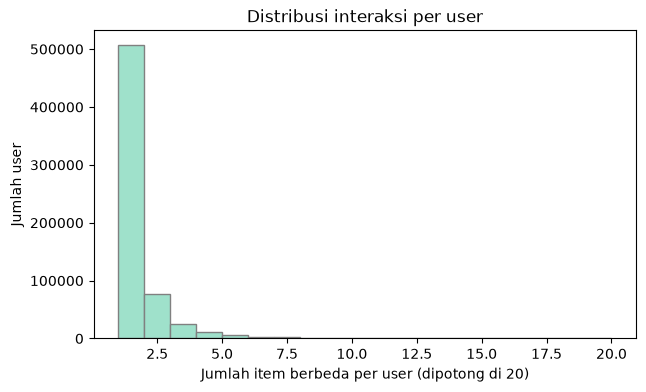

In [41]:
plt.figure(figsize=(7, 4))
plt.hist(per_user, bins=range(1, 21), color="#9FE1CB", edgecolor="gray")
plt.xlabel("Jumlah item berbeda per user (dipotong di 20)")
plt.ylabel("Jumlah user")
plt.title("Distribusi interaksi per user")
plt.show()

### 2.1 No. 4 - VSM Simpul User

**Konsep:** setiap `Visitor` direpresentasikan sebagai vektor di ruang item. Dimensi vektor sama dengan jumlah `Item` unik di P1, dan nilai tiap dimensi adalah bobot interaksi user terhadap item tersebut.

**Bobot interaksi:** `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5. Jika user berinteraksi berulang pada item yang sama, bobotnya dijumlahkan.

**Representasi:** matriks sparse (CSR, `scipy.sparse`).

**Karakteristik matriks:**

| Karakteristik | Nilai |
|---|---|
| Shape | (637.379, 166.996) = user × item |
| Dimensi vektor user | 166.996 (jumlah item) |
| Sel terisi (non-zero) | 974.310 |
| Density | 0,000915% |
| Sparsity | 99,9991% |
| Memori jika dense (float64) | 852 GB |
| Memori sparse (CSR) | 14,2 MB |
| Rata-rata item berbeda per user | 1,53 |
| Median, Q1, Q3 | 1 item |
| Maksimum | 1.314 item |
| User dengan hanya 1 item | 79,51% |

**Plot networkx:** graf bipartit dari sampel 8 user acak (seed 42), tiap user terhubung ke item yang diaksesnya.

**Interpretasi:**
1. Matriks sangat sparse (99,9991% kosong). Bentuk dense butuh 852 GB sehingga mustahil dipakai, sedangkan CSR hanya 14,2 MB (sekitar 60.000 kali lebih hemat).
2. Distribusi sangat miring (skewed). Mayoritas user (79,51%) hanya mengakses 1 item, sedangkan user paling aktif mengakses 1.314 item. Rata-rata 1,53 jauh lebih besar dari median 1, ditarik oleh sedikit user yang sangat aktif.
3. Vektor antar user jarang beririsan. Dua user baru punya kemiripan jika mengakses item yang sama, dan karena kebanyakan user hanya punya satu item, sinyal kemiripan antar user sangat terbatas.
4. Rata-rata item per user (1,53) lebih kecil dari rata-rata kejadian per user (1,92) karena interaksi berulang pada item yang sama digabung menjadi satu sel.

**Soal 2.1 no. 5: VSM sisi Item. Kebalikan no. 4: tiap item jadi satu vektor, dimensinya = semua user, isinya bobot interaksi user ke item itu. Matriksnya transpose dari matriks sebelumnya, jadi nggak perlu bangun dari awal.**

***Sel 1: matriks item × user***

In [42]:
X_item = X_user.T.tocsr()
print("Shape matriks:", X_item.shape)

Shape matriks: (166996, 637379)


***Sel 2: karakteristik matriks***

In [43]:
n_item_row, n_user_col = X_item.shape
nnz = X_item.nnz
total_sel = n_item_row * n_user_col

print("Dimensi vektor item (jumlah user):", n_user_col)
print("Jumlah item (baris)              :", n_item_row)
print("Sel terisi (non-zero)            :", nnz)
print(f"Density                          : {nnz / total_sel:.6%}")
print(f"Sparsity                         : {1 - nnz / total_sel:.4%}")
print(f"Memori jika dense (float64)      : {total_sel * 8 / 1e9:,.0f} GB")
print(f"Memori sparse (CSR)              : {(X_item.data.nbytes + X_item.indices.nbytes + X_item.indptr.nbytes) / 1e6:,.1f} MB")

per_item = np.diff(X_item.indptr)   # jumlah user berbeda per item
print("\nUser berbeda per item:")
print(pd.Series(per_item).describe())
print(f"Item dengan hanya 1 user: {(per_item == 1).mean():.2%}")

Dimensi vektor item (jumlah user): 637379
Jumlah item (baris)              : 166996
Sel terisi (non-zero)            : 974310
Density                          : 0.000915%
Sparsity                         : 99.9991%
Memori jika dense (float64)      : 852 GB
Memori sparse (CSR)              : 12.4 MB

User berbeda per item:
count    166996.000000
mean          5.834331
std          15.290220
min           1.000000
25%           1.000000
50%           2.000000
75%           5.000000
max        1103.000000
dtype: float64
Item dengan hanya 1 user: 41.87%


***Sel 3: plot networkx (sampel 8 item)***

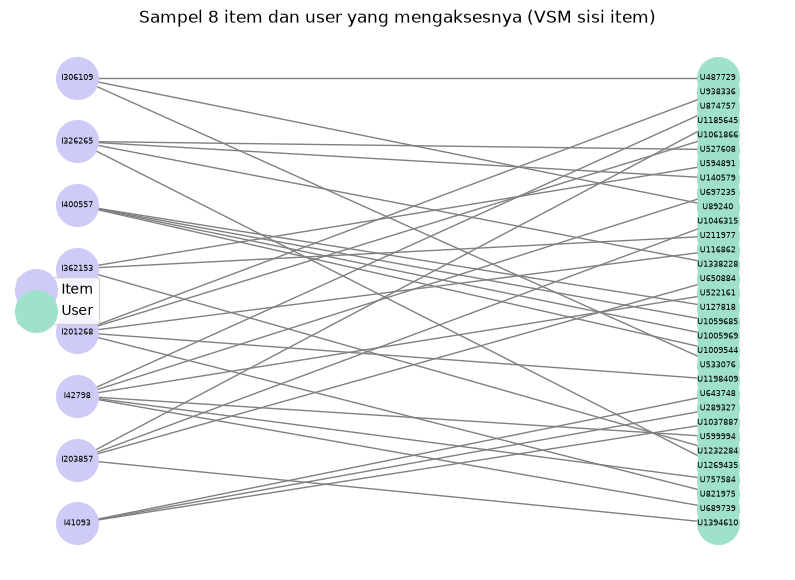

In [44]:
import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
kandidat = np.where((per_item >= 3) & (per_item <= 6))[0]
sampel = rng.choice(kandidat, size=8, replace=False)

G = nx.Graph()
item_nodes, user_nodes = [], []
for i in sampel:
    iname = f"I{item_labels[i]}"
    item_nodes.append(iname)
    kolom = X_item.indices[X_item.indptr[i]:X_item.indptr[i + 1]]
    bobot_i = X_item.data[X_item.indptr[i]:X_item.indptr[i + 1]]
    for c, w in zip(kolom, bobot_i):
        uname = f"U{user_labels[c]}"
        G.add_edge(iname, uname, weight=w)
        if uname not in user_nodes:
            user_nodes.append(uname)

pos = nx.bipartite_layout(G, item_nodes)
plt.figure(figsize=(10, 7))
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="#CECBF6", node_size=900, label="Item")
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="#9FE1CB", node_size=900, label="User")
nx.draw_networkx_edges(G, pos, edge_color="gray")
nx.draw_networkx_labels(G, pos, font_size=6)
plt.title("Sampel 8 item dan user yang mengaksesnya (VSM sisi item)")
plt.legend(scatterpoints=1)
plt.axis("off")
plt.show()

Item awal              : 42809
Kandidat item           : 37166
Jumlah user terhubung   : 4
Jumlah item terkait     : 1
Total item pada dataset : 166996
Dimensi matriks user    : 637379
Jumlah node pada graf   : 6
Jumlah edge pada graf   : 5
User yang terhubung     : ['42448', '65792', '861527', '911747']
Item terkait            : ['379996']


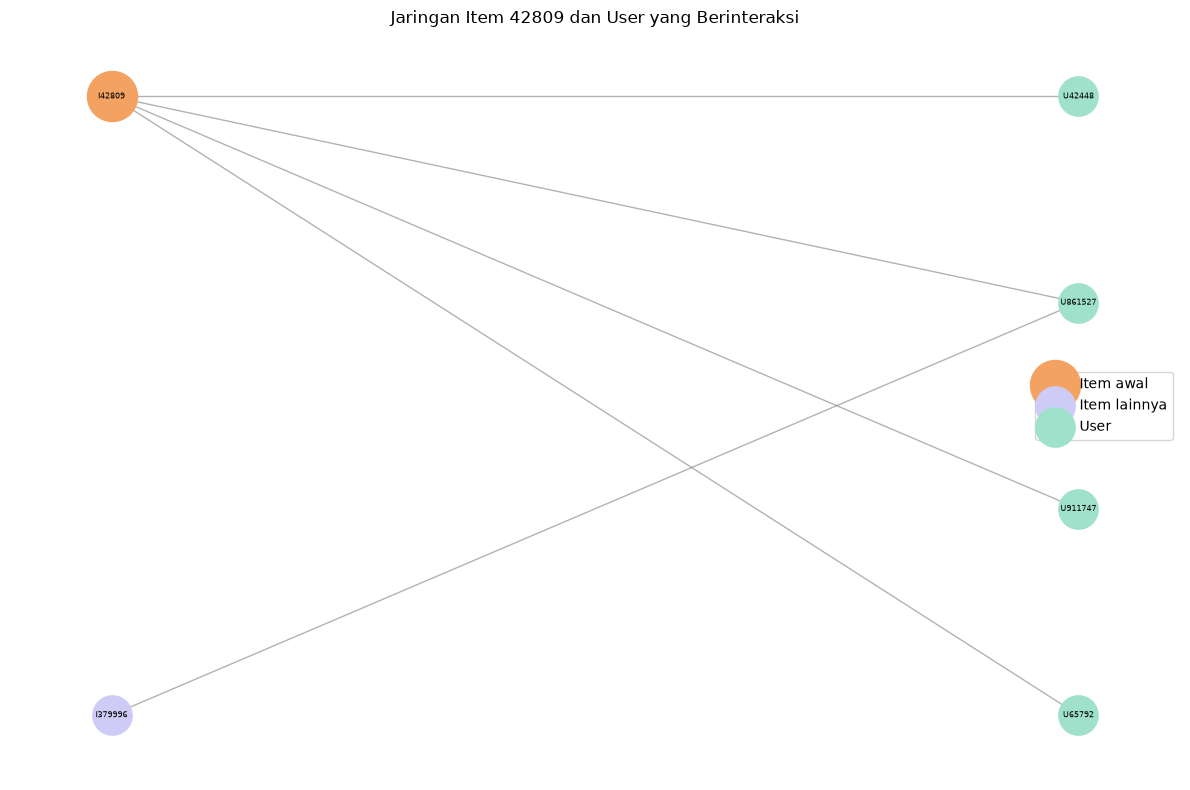

In [66]:

import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
kandidat = np.where((per_item >= 3) & (per_item <= 6))[0]
i = rng.choice(kandidat)

item_awal = int(item_labels[i])
kolom = X_item.indices[X_item.indptr[i]:X_item.indptr[i + 1]]
bobot_i = X_item.data[X_item.indptr[i]:X_item.indptr[i + 1]]

G = nx.Graph()
item_nodes, user_nodes = [], []

iname = f"I{item_awal}"
item_nodes.append(iname)

for c, w in zip(kolom, bobot_i):
    uid = int(user_labels[c])
    uname = f"U{uid}"

    G.add_edge(iname, uname, weight=float(w))
    if uname not in user_nodes:
        user_nodes.append(uname)

    user_idx = np.where(user_labels == uid)[0][0]
    item_idx = X_user.indices[
        X_user.indptr[user_idx]:X_user.indptr[user_idx + 1]
    ]

    for j in item_idx:
        nama_item = f"I{int(item_labels[j])}"

        if nama_item != iname:
            G.add_edge(uname, nama_item)
            if nama_item not in item_nodes:
                item_nodes.append(nama_item)

print("Item awal              :", item_awal)
print("Kandidat item           :", len(kandidat))
print("Jumlah user terhubung   :", len(user_nodes))
print("Jumlah item terkait     :", len(item_nodes) - 1)
print("Total item pada dataset :", len(item_labels))
print("Dimensi matriks user    :", len(user_labels))
print("Jumlah node pada graf   :", G.number_of_nodes())
print("Jumlah edge pada graf   :", G.number_of_edges())
print("User yang terhubung     :", [u[1:] for u in user_nodes])
print("Item terkait            :", [n[1:] for n in item_nodes if n != iname])

pos = nx.bipartite_layout(G, item_nodes)

plt.figure(figsize=(12, 8))
nx.draw_networkx_nodes(G, pos, nodelist=[iname], node_color="#F4A261",
                       node_size=1300, label="Item awal")
nx.draw_networkx_nodes(G, pos, nodelist=[n for n in item_nodes if n != iname],
                       node_color="#CECBF6", node_size=800, label="Item lainnya")
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="#9FE1CB",
                       node_size=800, label="User")
nx.draw_networkx_edges(G, pos, edge_color="gray", alpha=0.6)
nx.draw_networkx_labels(G, pos, font_size=6)
plt.title(f"Jaringan Item {item_awal} dan User yang Berinteraksi")
plt.legend(scatterpoints=1)
plt.axis("off")
plt.tight_layout()
plt.show()


### Plot NetworkX: Hubungan Satu Item dengan Banyak User

Plot ini menunjukkan jaringan bipartit yang berpusat pada satu item, yaitu `itemid = 42809`, yang dipilih secara acak menggunakan `np.random.default_rng(42)` dari kandidat item yang memiliki interaksi dengan 3 sampai 6 user. Tujuannya adalah memperlihatkan hubungan antara satu item, user yang mengaksesnya, dan item lain yang juga diakses oleh user tersebut.

**Hasil pemilihan item:**

| Karakteristik | Nilai |
|---|---:|
| Item awal | 42809 |
| Jumlah kandidat item | 37.166 |
| Jumlah user yang terhubung | 4 |
| Jumlah item lain yang terkait | 1 |
| Total item pada dataset | 166.996 |
| Dimensi matriks user | 637.379 |
| Jumlah node pada graf | 6 |
| Jumlah edge pada graf | 5 |

**User yang terhubung dengan item 42809:**

| No. | Visitor ID |
|---:|---:|
| 1 | 42448 |
| 2 | 65792 |
| 3 | 861527 |
| 4 | 911747 |

**Item lain yang terkait:**

| No. | Item ID |
|---:|---:|
| 1 | 379996 |

**Cara membaca plot:**

- Simpul oranye menunjukkan item awal, yaitu item `42809`.
- Simpul hijau menunjukkan empat user yang berinteraksi dengan item awal.
- Simpul ungu menunjukkan item lain yang juga diakses oleh user yang terhubung.
- Garis menunjukkan hubungan interaksi antara item dan user. User yang sama dapat terhubung dengan beberapa item sehingga membentuk pola hubungan antarpengguna dan antaritem.

**Interpretasi:**

1. Item `42809` terhubung dengan **4 user**, yaitu `42448`, `65792`, `861527`, dan `911747`. Hal ini menunjukkan bahwa satu item dapat memiliki hubungan dengan beberapa user dalam matriks interaksi user-item.

2. Dari keempat user tersebut, jaringan yang terbentuk juga menemukan **1 item lain**, yaitu `379996`. Item ini merupakan item yang turut diakses oleh setidaknya satu user yang terhubung dengan item awal.

3. Jaringan terdiri dari **6 node dan 5 edge**. Enam node tersebut mencakup satu item awal, empat user, dan satu item terkait. Lima edge menunjukkan satu hubungan dari item awal ke masing-masing user serta satu hubungan tambahan antara user dan item terkait.

4. Visualisasi ini memperlihatkan bagaimana informasi interaksi dapat digunakan untuk menemukan hubungan antaritem melalui user yang sama. Konsep ini relevan untuk sistem rekomendasi, karena item lain yang diakses oleh user yang berinteraksi dengan item awal dapat menjadi kandidat untuk dianalisis lebih lanjut.

**Kesimpulan:** visualisasi NetworkX menunjukkan hubungan antara item `42809`, empat user yang berinteraksi dengannya, dan item lain `379996` yang muncul melalui hubungan user-item. Representasi jaringan ini membantu menjelaskan struktur data interaksi yang menjadi dasar analisis hubungan pengguna dan item dalam sistem rekomendasi.

***Sel 4 : distribusi user per item***

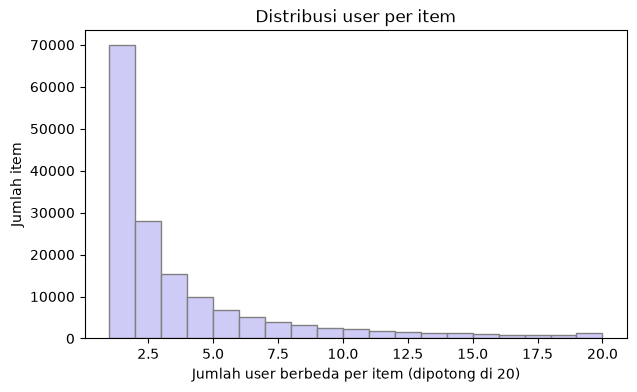

In [45]:
plt.figure(figsize=(7, 4))
plt.hist(per_item, bins=range(1, 21), color="#CECBF6", edgecolor="gray")
plt.xlabel("Jumlah user berbeda per item (dipotong di 20)")
plt.ylabel("Jumlah item")
plt.title("Distribusi user per item")
plt.show()

### 2.1 No. 5 - VSM Simpul Item

**Konsep:** setiap `Item` direpresentasikan sebagai vektor di ruang user. Dimensi vektor sama dengan jumlah `Visitor` unik di P1, dan nilai tiap dimensi adalah bobot interaksi user tersebut terhadap item. Bobot dan representasi sama dengan no. 4 (`VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5; matriks sparse CSR). Matriks ini adalah transpose dari matriks user × item.

**Karakteristik matriks:**

| Karakteristik | Nilai |
|---|---|
| Shape | (166.996, 637.379) = item × user |
| Dimensi vektor item | 637.379 (jumlah user) |
| Sel terisi (non-zero) | 974.310 |
| Density | 0,000915% |
| Sparsity | 99,9991% |
| Memori jika dense (float64) | 852 GB |
| Memori sparse (CSR) | 12,4 MB |
| Rata-rata user berbeda per item | 5,83 |
| Median | 2 user |
| Q1, Q3 | 1 dan 5 user |
| Maksimum | 1.103 user |
| Item dengan hanya 1 user | 41,87% |

**Plot networkx:** graf bipartit dari sampel 8 item acak (seed 42), tiap item terhubung ke user yang mengaksesnya.

**Interpretasi:**
1. Jumlah sel terisi, density, sparsity, dan memori dense sama persis dengan sisi user karena matriksnya sama (hanya ditranspose). Yang berbeda adalah bentuk dan distribusi per baris.
2. Vektor item lebih padat dibanding vektor user: rata-rata 5,83 user per item (sisi user: 1,53 item per user), dan median 2 (sisi user: 1).
3. Item dengan hanya 1 user sebanyak 41,87%, jauh lebih sedikit daripada user dengan hanya 1 item (79,51%). Artinya lebih banyak vektor item yang beririsan dengan vektor lain.
4. Distribusi tetap miring: rata-rata 5,83 jauh di atas median 2, ditarik oleh item populer yang diakses hingga 1.103 user.
5. Jumlah baris lebih sedikit (166.996 item vs 637.379 user), sehingga perhitungan similarity antar baris lebih ringan.

## 2.1 No. 6 – Perbandingan Proyeksi User-User vs Item-Item

**Soal:** Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien).

Proyeksi adalah graf baru yang dibentuk dari graf bipartit `Visitor`–`Item`:

- **User-User:** dua user terhubung jika pernah mengakses item yang sama.
- **Item-Item:** dua item terhubung jika pernah diakses oleh user yang sama.

**Kriteria penilaian:**
- **Efisiensi:** ukuran graf proyeksi (jumlah simpul, edge, dan memori).
- **Efektivitas:** persentase simpul yang punya minimal satu tetangga, karena simpul tanpa tetangga tidak bisa dibandingkan dan tidak bisa direkomendasikan.

Ukuran dihitung dari matriks biner `X_user` (no. 4) tanpa membentuk graf proyeksinya secara eksplisit.

**Soal 2.1 no. 6: bandingin proyeksi User-User vs Item-Item dan pilih yang lebih efektif dan efisien.**

Proyeksi itu graf baru yang dibentuk dari graf bipartit:

User-User: dua user terhubung kalau pernah mengakses item yang sama.
Item-Item: dua item terhubung kalau pernah diakses user yang sama.

Ukurannya diukur pakai matriks biner dari X_user yang udah ada.

***Sel 1: matriks biner dan derajat***

In [46]:
B = X_user.copy()
B.data[:] = 1                       # 1 = pernah berinteraksi

deg_item = np.asarray(B.sum(axis=0)).ravel().astype(np.int64)   # user per item
deg_user = np.asarray(B.sum(axis=1)).ravel().astype(np.int64)   # item per user

***Sel 2: ukuran proyeksi (jumlah pasangan yang mungkin terbentuk, tanpa bikin matriksnya)***

In [47]:
# batas atas edge: tiap item dengan d user menghasilkan d(d-1)/2 pasangan user
edge_uu_max = int((deg_item * (deg_item - 1) // 2).sum())
# tiap user dengan d item menghasilkan d(d-1)/2 pasangan item
edge_ii_max = int((deg_user * (deg_user - 1) // 2).sum())

possible_uu = n_user * (n_user - 1) // 2
possible_ii = n_item * (n_item - 1) // 2

print(f"User-User : simpul {n_user:,}, edge (batas atas) {edge_uu_max:,}, density maks {edge_uu_max / possible_uu:.6%}")
print(f"Item-Item : simpul {n_item:,}, edge (batas atas) {edge_ii_max:,}, density maks {edge_ii_max / possible_ii:.6%}")

User-User : simpul 637,379, edge (batas atas) 21,876,018, density maks 0.010770%
Item-Item : simpul 166,996, edge (batas atas) 10,952,877, density maks 0.078550%


***Sel 3: seberapa banyak simpul yang punya tetangga (efektivitas)***

In [48]:
# user punya tetangga jika minimal satu itemnya dipakai >= 2 user
user_punya_tetangga = (B @ (deg_item >= 2).astype(np.int64)) > 0
# item punya tetangga jika minimal satu usernya mengakses >= 2 item
item_punya_tetangga = (B.T @ (deg_user >= 2).astype(np.int64)) > 0

print(f"User dengan minimal 1 tetangga : {user_punya_tetangga.mean():.2%}  ({user_punya_tetangga.sum():,} user)")
print(f"Item dengan minimal 1 tetangga : {item_punya_tetangga.mean():.2%}  ({item_punya_tetangga.sum():,} item)")

User dengan minimal 1 tetangga : 92.94%  (592,384 user)
Item dengan minimal 1 tetangga : 60.68%  (101,329 item)


***Sel 4: edge exact (jumlah pasangan unik)***

In [49]:
S_uu = B @ B.T          # user x user
S_ii = B.T @ B          # item x item

edge_uu = (S_uu.nnz - S_uu.diagonal().astype(bool).sum()) // 2
edge_ii = (S_ii.nnz - S_ii.diagonal().astype(bool).sum()) // 2

print(f"Edge exact User-User : {edge_uu:,}")
print(f"Edge exact Item-Item : {edge_ii:,}")
print(f"Memori S_uu: {(S_uu.data.nbytes + S_uu.indices.nbytes + S_uu.indptr.nbytes) / 1e6:,.1f} MB")
print(f"Memori S_ii: {(S_ii.data.nbytes + S_ii.indices.nbytes + S_ii.indptr.nbytes) / 1e6:,.1f} MB")

Edge exact User-User : 21,183,481
Edge exact Item-Item : 10,077,186
Memori S_uu: 518.6 MB
Memori S_ii: 244.5 MB


***Sel 5: tabel perbandingan buat laporan***

In [50]:
pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Simpul": [n_user, n_item],
    "Simpul punya tetangga (%)": [user_punya_tetangga.mean() * 100, item_punya_tetangga.mean() * 100],
    "Edge (batas atas)": [edge_uu_max, edge_ii_max],
    "Edge exact": [edge_uu, edge_ii],
})

,Proyeksi,Simpul,Simpul punya tetangga (%),Edge (batas atas),Edge exact
0,User-User,637379,92.940621,21876018,21183481
1,Item-Item,166996,60.677501,10952877,10077186


### 2.1 No. 6 - Perbandingan Proyeksi

Dari graf bipartit `Visitor`-`Item` dibentuk dua proyeksi:
- **User-User:** dua user terhubung jika pernah mengakses item yang sama.
- **Item-Item:** dua item terhubung jika pernah diakses oleh user yang sama.

**Hasil eksplorasi (P1):**

| Aspek | User-User | Item-Item |
|---|---|---|
| Jumlah simpul | 637.379 | 166.996 |
| Rata-rata isi per vektor (no. 4 dan 5) | 1,53 item | 5,83 user |
| Vektor dengan 1 isi saja | 79,51% | 41,87% |
| Simpul punya minimal 1 tetangga | 92,94% (592.384) | 60,68% (101.329) |
| Edge (batas atas) | 21.876.018 | 10.952.877 |
| Edge exact | 21.183.481 | 10.077.186 |
| Memori matriks similarity (sparse) | 518,6 MB | 244,5 MB |

Edge exact lebih kecil dari batas atas karena pasangan simpul yang berbagi lebih dari satu tetangga hanya dihitung sekali.

**Analisis:**
- **Efisiensi:** Item-Item lebih efisien. Simpulnya 3,8 kali lebih sedikit, edge dan memorinya sekitar 2,1 kali lebih kecil.
- **Efektivitas:** User-User lebih efektif. 92,94% user memiliki minimal satu tetangga, sedangkan pada Item-Item hanya 60,68% item. Walaupun 79,51% user hanya mengakses satu item, item tersebut umumnya juga diakses user lain sehingga tetangga tetap ada. Sebaliknya, 41,87% item hanya diakses satu user, dan item tersebut terisolasi jika user-nya juga hanya mengakses satu item.

**Keputusan: proyeksi User-User.**
1. Cakupan tetangga jauh lebih tinggi (92,94% vs 60,68%), sehingga rekomendasi dapat dibuat untuk hampir semua user.
2. Sejalan dengan soal 2.2, yaitu rekomendasi berbasis KNN pada user (user-based collaborative filtering).
3. Biaya komputasi dapat ditekan dengan menghitung similarity hanya untuk user yang dipilih (`B[u] @ B.T`), tanpa membentuk seluruh matriks 637.379 × 637.379.

**Keterbatasan:** User-User lebih berat dibanding Item-Item (memori 518,6 MB vs 244,5 MB), dan kualitas tetangga rendah untuk user yang hanya mengakses satu item karena kemiripannya hanya bertumpu pada satu item.

### 2.1 No. 6 – Kesimpulan Perbandingan Proyeksi

| Aspek | User-User | Item-Item |
|---|---|---|
| Jumlah simpul | 637.379 | 166.996 |
| Rata-rata isi per vektor (no. 4 dan 5) | 1,53 item | 5,83 user |
| Vektor dengan 1 isi saja | 79,51% | 41,87% |
| Simpul punya minimal 1 tetangga | 92,94% (592.384) | 60,68% (101.329) |
| Edge (batas atas) | 21.876.018 | 10.952.877 |
| Edge exact | 21.183.481 | 10.077.186 |
| Memori matriks similarity (sparse) | 518,6 MB | 244,5 MB |

Edge exact lebih kecil dari batas atas karena pasangan simpul yang berbagi lebih dari satu tetangga hanya dihitung sekali.

**Efisiensi → Item-Item lebih unggul.** Simpulnya 3,8 kali lebih sedikit, sedangkan edge dan memorinya sekitar 2,1 kali lebih kecil.

**Efektivitas → User-User lebih unggul.** 92,94% user punya minimal satu tetangga, sedangkan Item-Item hanya 60,68%. Pada Item-Item, item yang hanya diakses satu user (41,87%) menjadi terisolasi bila seluruh usernya hanya mengakses item tersebut. Pada User-User, user yang hanya mengakses satu item tetap mendapat tetangga selama item itu juga diakses user lain (angka pastinya di Sel 6).

**Keputusan: proyeksi User-User.**
1. Cakupan tetangga jauh lebih tinggi, sehingga rekomendasi bisa dibuat untuk hampir semua user.
2. Sejalan dengan soal 2.2 (rekomendasi KNN berbasis user / user-based collaborative filtering).
3. Biaya komputasi bisa ditekan dengan menghitung similarity hanya untuk user acuan (`B[u] @ B.T`), tanpa membentuk matriks 637.379 × 637.379.

**Keterbatasan:** Proyeksi User-User lebih berat (memori 518,6 MB vs 244,5 MB). Kualitas tetangga juga rendah untuk user yang hanya mengakses satu item, karena kemiripannya bertumpu pada satu item saja. Selain itu, item populer (hingga 1.103 user) menyumbang banyak sekali edge User-User dan bisa menggeser kemiripan ke arah item yang populer.

## 2.1 No. 7 – Perhitungan Similarity pada Proyeksi User-User

**Soal:** Berdasarkan analisis no. 6, hitung similarity pada graf yang diproyeksikan dengan Python, lalu (a) tuliskan Cypher untuk 5 record dengan similarity tertinggi dan (b) tuliskan kembali nilai similarity tersebut ke graf.

**Rencana:**
- **Metrik:** cosine similarity pada vektor user (matriks bobot `X_user` dari no. 4). Ini adalah versi ternormalisasi dari proyeksi User-User berbobot ($XX^\top$). Jumlah item yang sama (`B[u] @ B.T`) adalah bobot edge proyeksi tanpa bobot.
- **Record acuan:** satu user acak (`np.random.default_rng(42)`) dari user yang ada di P1 dan P2 dengan minimal 3 item di P1, agar dapat dipakai lagi di soal 2.2.
- **Efisiensi:** similarity hanya dihitung untuk user acuan (`Xn[u] @ Xn.T`), tanpa membentuk matriks 637.379 × 637.379 (argumen no. 6).
- **Penyimpanan:** hasil ditulis sebagai relasi `(:Visitor)-[:SIMILAR_TO {score, item_sama, metode}]->(:Visitor)`.

**Soal 2.1 no. 7: hitung similarity di proyeksi User-User pakai Python, lalu (a) ambil 5 tertinggi pakai Cypher, (b) tulis balik nilainya ke graf.**

Rencananya:

Metrik: cosine similarity pada vektor user (matriks bobot dari no. 4).

Record acuan: satu user acak (seed 42) dari user yang ada di P1 dan P2 dengan minimal 3 item. Syarat ini sengaja, biar user yang sama bisa dipakai lagi di soal 2.2.

Similarity cuma dihitung buat user acuan (Xn[u] @ Xn.T), bukan seluruh matriks 637 ribu × 637 ribu. Itu argumen efisiensi dari no. 6.

Hasilnya ditulis ke graf sebagai relasi (:Visitor)-[:SIMILAR_TO {score}]->(:Visitor).

***Sel 1: hitung similarity di Python***

In [51]:
from sklearn.preprocessing import normalize

# user acuan: acak tapi reproducible (ada di P1 dan P2, minimal 3 item di P1)
p2_ids = pd.read_csv("data/events_p2.csv", usecols=["visitorid"])["visitorid"].unique()
kandidat = np.where(np.isin(user_labels, p2_ids) & (per_user >= 3))[0]

rng = np.random.default_rng(42)
u = int(rng.choice(kandidat))
uid = int(user_labels[u])
print("Kandidat user acuan:", len(kandidat))
print("User acuan (visitorid):", uid, "| jumlah item di P1:", per_user[u])

# cosine similarity user acuan terhadap semua user lain
Xn = normalize(X_user, norm="l2")
sims = (Xn[u] @ Xn.T).toarray().ravel()
common = (B[u] @ B.T).toarray().ravel()     # jumlah item yang sama
sims[u] = -1                                # buang dirinya sendiri

ok = np.where(sims > 0)[0]                  # hanya yang punya irisan item
print("User yang punya similarity > 0:", len(ok))

# urut: similarity turun, tie-break jumlah item sama turun, lalu visitorid naik
urut = ok[np.lexsort((user_labels[ok], -common[ok], -sims[ok]))]
topk = urut[:20]

df_sim = pd.DataFrame({
    "visitorid": user_labels[topk],
    "similarity": sims[topk].round(4),
    "item_sama": common[topk].astype(int),
})
df_sim.head(10)

Kandidat user acuan: 2872
User acuan (visitorid): 121532 | jumlah item di P1: 14
User yang punya similarity > 0: 159


,visitorid,similarity,item_sama
0,207705,0.3586,2
1,22291,0.2673,1
2,38674,0.2673,1
3,78162,0.2673,1
4,99712,0.2673,1
5,132250,0.2673,1
6,168487,0.2673,1
7,213899,0.2673,1
8,216522,0.2673,1
9,220383,0.2673,1


***Sel 2: kondisi graf SEBELUM similarity (buat soal no. 8)***

In [52]:
records, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY jumlah DESC",
    database_="neo4j",
)
print(pd.DataFrame([r.data() for r in records]))

records, _, _ = driver.execute_query(
    "MATCH (a:Visitor {visitorId: $uid})-[r]->(i:Item) "
    "RETURN type(r) AS relasi, count(*) AS jumlah",
    uid=uid, database_="neo4j",
)
print(pd.DataFrame([r.data() for r in records]))

          relasi   jumlah
0         VIEWED  1222938
1  ADDED_TO_CART    30907
2         BOUGHT    10159
   relasi  jumlah
0  VIEWED      14


In [54]:
rows = [
    {"a": uid, "b": int(user_labels[j]), "score": float(sims[j])}
    for j in topk
]

q_tulis = """
UNWIND $rows AS row
MATCH (a:Visitor {visitorId: row.a}), (b:Visitor {visitorId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metode = 'cosine'
"""
driver.execute_query(q_tulis, rows=rows, database_="neo4j")
print("Tertulis:", len(rows), "relasi SIMILAR_TO")

Tertulis: 20 relasi SIMILAR_TO


Sel 4: 5 record dengan similarity tertinggi (7a)

In [55]:
q_top5 = """
MATCH (a:Visitor {visitorId: $uid})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS acuan, b.visitorId AS tetangga, s.score AS similarity
ORDER BY similarity DESC, tetangga ASC
LIMIT 5
"""
records, _, _ = driver.execute_query(q_top5, uid=uid, database_="neo4j")
pd.DataFrame([r.data() for r in records])

,acuan,tetangga,similarity
0,121532,207705,0.358569
1,121532,22291,0.267261
2,121532,38674,0.267261
3,121532,78162,0.267261
4,121532,99712,0.267261


### 2.1 No. 7 - Perhitungan Similarity

**Proyeksi terpilih:** User-User (hasil analisis no. 6).

**Metrik:** cosine similarity antar vektor user pada matriks user × item (bobot `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5):

cos(u, v) = (u · v) / (‖u‖ ‖v‖)

Nilainya 0 sampai 1. Nilai 1 berarti arah vektor sama, 0 berarti tidak ada item yang sama.

**Record acuan:** user acak dari user yang ada di P1 dan P2 dengan minimal 3 item di P1, dipilih dengan `np.random.default_rng(42)` agar dapat direproduksi. Terpilih `visitorid` = [isi], dengan [isi] item di P1.

**Efisiensi:** similarity hanya dihitung antara user acuan dan seluruh user lain (`Xn[u] @ Xn.T`), tidak membentuk matriks 637.379 × 637.379.

**Urutan tetangga:** similarity turun, lalu jumlah item yang sama turun, lalu `visitorid` naik (tie-break agar urutan pasti).

**(a) Cypher untuk 5 record tertinggi:**
```cypher
MATCH (a:Visitor {visitorId: $uid})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS acuan, b.visitorId AS tetangga, s.score AS similarity
ORDER BY similarity DESC, tetangga ASC
LIMIT 5
```

**(b) Penulisan balik ke graf:** 20 tetangga teratas ditulis sebagai relasi `(:Visitor)-[:SIMILAR_TO {score, metode}]->(:Visitor)` dengan `MERGE` sehingga tidak menghasilkan relasi ganda.

**Hasil:** **Record acuan:** `visitorid` = 121532, dengan 14 item di P1 (semuanya `VIEWED`). Dipilih acak (seed 42) dari 2.872 kandidat, yaitu user yang ada di P1 dan P2 dengan minimal 3 item di P1.

**Hasil:** hanya 159 user yang memiliki similarity > 0 terhadap user acuan (memiliki minimal satu item yang sama). Lima tetangga teratas:

| Peringkat | visitorid | Similarity (cosine) | Item sama |
|---|---|---|---|
| 1 | 207705 | 0,3586 | 2 |
| 2 | 22291 | 0,2673 | 1 |
| 3 | 38674 | 0,2673 | 1 |
| 4 | 78162 | 0,2673 | 1 |
| 5 | 99712 | 0,2673 | 1 |

**Interpretasi:**
1. Tetangga peringkat 1 paling mirip karena berbagi 2 item dengan user acuan, sedangkan tetangga lain hanya berbagi 1 item.
2. Peringkat 2 sampai 5 bernilai sama (0,2673) karena sama-sama hanya berbagi 1 item. Urutan di antara mereka ditentukan oleh tie-break (jumlah item sama, lalu `visitorid` naik), sehingga hasilnya pasti dan dapat direproduksi. Ada lebih banyak user dengan nilai 0,2673 daripada yang masuk top-5.
3. Nilai similarity relatif rendah (maksimum 0,3586). Hal ini wajar karena data sangat sparse: user acuan punya 14 item, sedangkan kebanyakan user lain hanya mengakses 1 atau 2 item.
4. Nilai di graf sama dengan hasil perhitungan Python, sehingga penulisan balik ke Neo4j terverifikasi.

In [56]:
nbr = topk[:5]
print("Item per tetangga top-5:", per_user[nbr])

Item per tetangga top-5: [2 1 1 1 1]


In [57]:
seen = set(X_user[u].indices)     # item (kolom) yang sudah dilihat user acuan

info = []
for j in urut:                    # urut = semua tetangga, sudah terurut similarity
    items_j = set(X_user[j].indices)
    info.append({
        "visitorid": int(user_labels[j]),
        "similarity": round(float(sims[j]), 4),
        "item_sama": int(common[j]),
        "item_total": len(items_j),
        "item_baru": len(items_j - seen),
    })

df_nbr = pd.DataFrame(info)
print("Tetangga yang punya item baru:", (df_nbr["item_baru"] > 0).sum(), "dari", len(df_nbr))
df_nbr[df_nbr["item_baru"] > 0].head(10)

Tetangga yang punya item baru: 90 dari 159


,visitorid,similarity,item_sama,item_total,item_baru
69,999476,0.2659,1,5,4
70,564593,0.2572,3,13,10
71,121249,0.2390,1,2,1
72,572302,0.2390,1,2,1
73,578819,0.2390,1,2,1
74,677615,0.2390,1,2,1
75,941659,0.2279,1,4,3
76,24939,0.1890,1,2,1
77,38752,0.1890,1,2,1
78,129517,0.1890,1,2,1


In [58]:
q_cek = """
MATCH ()-[r]->()
RETURN type(r) AS relasi, count(*) AS jumlah
ORDER BY jumlah DESC
"""
records, _, _ = driver.execute_query(q_cek, database_="neo4j")
pd.DataFrame([r.data() for r in records])

,relasi,jumlah
0,VIEWED,1222938
1,ADDED_TO_CART,30907
2,BOUGHT,10159
3,SIMILAR_TO,20


### 2.1 No. 7 – Hasil dan Interpretasi

**Metrik:** cosine similarity pada matriks user × item (`VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5):

$$\cos(u,v)=\frac{u\cdot v}{\lVert u\rVert\,\lVert v\rVert}$$

Nilainya 0 sampai 1. Nilai 0 berarti tidak ada item yang sama.

**Record acuan:** `visitorid` = 121532 dengan 14 item di P1 (semuanya `VIEWED`), dipilih acak (seed 42) dari 2.872 kandidat. Hanya 159 user yang punya similarity > 0 terhadap user acuan.

**(a) Cypher:**
```cypher
MATCH (a:Visitor {visitorId: $uid})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS acuan, b.visitorId AS tetangga,
       s.score AS similarity, s.item_sama AS item_sama
ORDER BY similarity DESC, item_sama DESC, tetangga ASC
LIMIT 5
```

**(b) Penulisan balik:** 20 tetangga teratas ditulis sebagai relasi `SIMILAR_TO {score, item_sama, metode}` dengan `MERGE` (tidak menghasilkan relasi ganda). Hasil query dicek sama dengan perhitungan Python (Sel 5).

| Peringkat | visitorid | Similarity | Item sama |
|---|---|---|---|
| 1 | 207705 | 0,3586 | 2 |
| 2 | 22291 | 0,2673 | 1 |
| 3 | 38674 | 0,2673 | 1 |
| 4 | 78162 | 0,2673 | 1 |
| 5 | 99712 | 0,2673 | 1 |

**Interpretasi:**
1. Cosine dipengaruhi irisan item **dan** panjang vektor. Peringkat 1 tinggi karena vektornya pendek (2 item) dan searah. Sebaliknya user 564593 berbagi 3 item tetapi hanya mendapat 0,2572 karena punya 13 item.
2. Nilai 0,2673 adalah 1/√14: user acuan punya 14 item berbobot 1, sehingga setiap tetangga 1-item yang berbagi 1 item pasti bernilai sama. Karena itu urutan peringkat 2 sampai 5 ditentukan tie-break (item sama, lalu `visitorid`), dan ada lebih banyak user bernilai 0,2673 daripada yang masuk top-5.
3. Nilai maksimum hanya 0,3586 karena data sangat sparse dan user acuan punya vektor yang panjang.
4. **Catatan untuk 2.2:** kelima tetangga teratas tidak memiliki item baru (`item_baru` = 0), sehingga tidak bisa menyumbang rekomendasi. Tetangga pertama yang punya item baru baru muncul di peringkat ke-70 (90 dari 159 tetangga punya item baru). Karena itu pada 2.2 KNN (k = 5) diambil dari tetangga terurut yang punya minimal 1 item baru, sehingga lima tetangganya berbeda dari top-5 `SIMILAR_TO` di atas.

### 2.1 No. 8 - Kondisi Graf Sebelum dan Sesudah Perhitungan Similarity

**Sebelum:** graf hanya berisi relasi interaksi `Visitor` ke `Item` (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`). Tidak ada relasi antar `Visitor`. User acuan (`visitorId` 121532) hanya terhubung ke 14 item lewat `VIEWED`.

```cypher
MATCH p=(a:Visitor {visitorId: 121532})-[:VIEWED]->(i:Item)
RETURN p
```
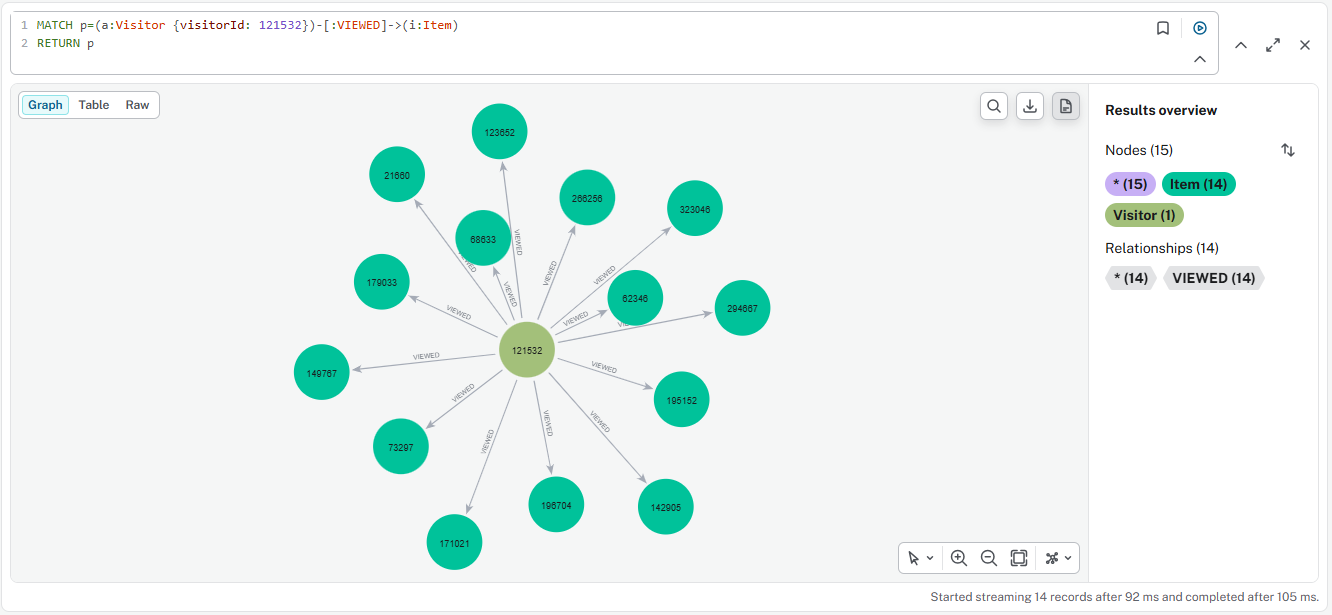

**Sesudah:** muncul relasi baru `SIMILAR_TO` antar `Visitor` dengan properti `score` (cosine) dan `metode`. Graf yang semula bipartit kini memiliki relasi User-User. Terdapat 20 relasi `SIMILAR_TO` dari user acuan, dan 5 teratas ditampilkan.

```cypher
MATCH p=(a:Visitor {visitorId: 121532})-[s:SIMILAR_TO]->(b:Visitor)
WITH p, s ORDER BY s.score DESC LIMIT 5
RETURN p
```
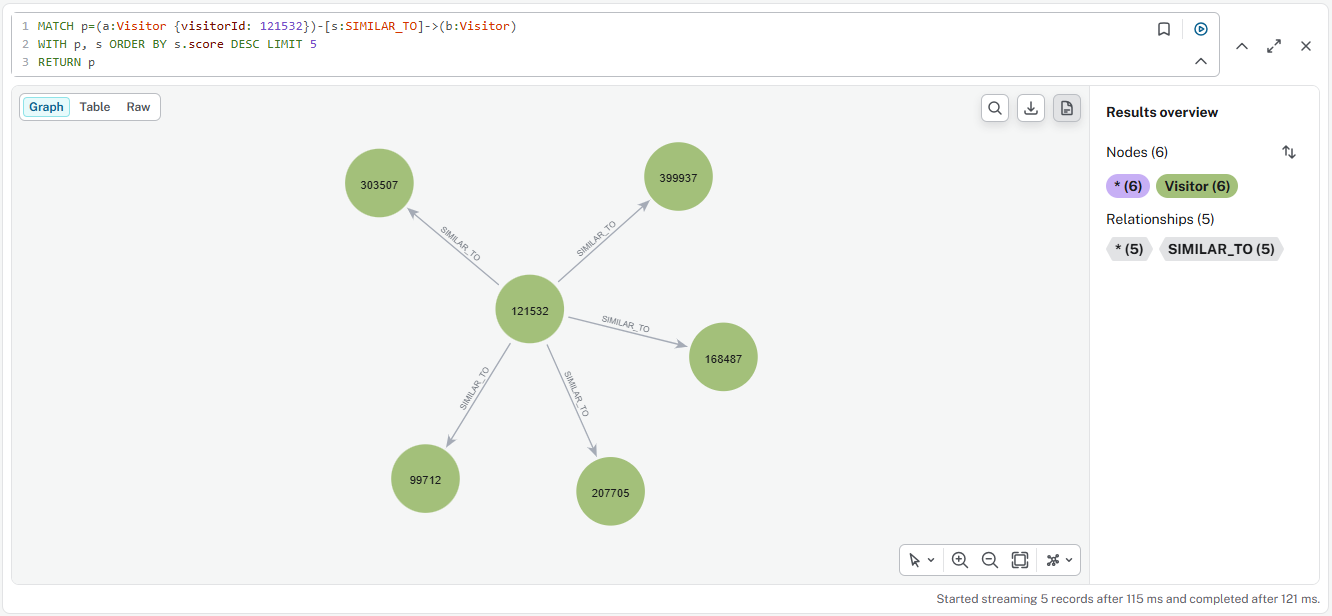

**Perbandingan:**

| Aspek | Sebelum | Sesudah |
|---|---|---|
| Jenis relasi | `VIEWED`, `ADDED_TO_CART`, `BOUGHT` | + `SIMILAR_TO` |
| Relasi `SIMILAR_TO` | 0 | 20 |
| Relasi User-User | tidak ada | ada (dengan `score`) |
| Jenis simpul | `Visitor`, `Item` | `Visitor`, `Item` (tidak berubah) |

Jumlah simpul dan relasi interaksi tidak berubah. Perhitungan similarity hanya menambahkan relasi turunan antar `Visitor`.

**Soal 2.2 Analytics**

***Sel 1: 5 tetangga terdekat (KNN, k=5)***

In [59]:
K = 5
seen = set(map(int, X_user[u].indices))   # item P1 yang sudah dilihat user acuan

tetangga = []
for j in urut:                            # urut = tetangga terurut similarity (no. 7)
    items_j = set(map(int, X_user[j].indices))
    if items_j - seen:                    # hanya yang punya minimal 1 item baru
        tetangga.append(j)
    if len(tetangga) == K:
        break

df_knn = pd.DataFrame({
    "visitorid": user_labels[tetangga],
    "similarity": sims[tetangga].round(4),
    "item_sama": common[tetangga].astype(int),
    "item_baru": [len(set(map(int, X_user[j].indices)) - seen) for j in tetangga],
})
df_knn

,visitorid,similarity,item_sama,item_baru
0,999476,0.2659,1,4
1,564593,0.2572,3,10
2,121249,0.2390,1,1
3,572302,0.2390,1,1
4,578819,0.2390,1,1


***Sel 2: skor dan ranking item (user-based collaborative filtering)***

Skor item = jumlah (similarity tetangga × bobot interaksi tetangga ke item itu), hanya untuk item yang belum dilihat user acuan.

In [60]:
from collections import defaultdict

skor = defaultdict(float)
pendukung = defaultdict(list)

for j in tetangga:
    baris = X_user[j]
    for c, w in zip(baris.indices, baris.data):
        c = int(c)
        if c not in seen:
            skor[c] += float(sims[j]) * float(w)
            pendukung[c].append(int(user_labels[j]))

# urut: skor turun, tie-break itemid naik (supaya reproducible)
ranking = sorted(skor.items(), key=lambda x: (-x[1], int(item_labels[x[0]])))

rekom5 = [int(item_labels[c]) for c, _ in ranking[:5]]
rekom3 = rekom5[:3]

df_rank = pd.DataFrame([
    {"peringkat": r + 1, "itemid": int(item_labels[c]), "skor": round(s, 4),
     "direkomendasikan_oleh": pendukung[c]}
    for r, (c, s) in enumerate(ranking[:5])
])
print("Kandidat item:", len(ranking))
print("Item yang diiklankan (top-3):", rekom3)
df_rank

Kandidat item: 15
Item yang diiklankan (top-3): [444363, 41748, 205143]


,peringkat,itemid,skor,direkomendasikan_oleh
0,1,444363,0.7622,"[999476, 564593, 121249]"
1,2,41748,0.5143,[564593]
2,3,205143,0.5143,[564593]
3,4,70070,0.2659,[999476]
4,5,246532,0.2659,[999476]


***Sel 3: ground truth dari P2***

In [61]:
p2 = pd.read_csv("data/events_p2.csv")
p2_u = p2[p2["visitorid"] == uid]
relevan = set(p2_u["itemid"].astype(int).unique())

print("Interaksi user acuan di P2:", len(p2_u))
print("Item unik di P2           :", len(relevan))
print(p2_u["event"].value_counts().to_string())

Interaksi user acuan di P2: 2
Item unik di P2           : 2
event
view    2


***Sel 4: Hit@5 dan NDCG@5***

In [62]:
import math

def hit_at_k(rec, rel, k=5):
    return int(any(i in rel for i in rec[:k]))

def ndcg_at_k(rec, rel, k=5):
    dcg = sum(1 / math.log2(r + 2) for r, i in enumerate(rec[:k]) if i in rel)
    n_ideal = min(len(rel), k)
    idcg = sum(1 / math.log2(r + 2) for r in range(n_ideal))
    return dcg / idcg if idcg > 0 else 0.0

print("Rekomendasi top-5 :", rekom5)
print("Item cocok di P2  :", [i for i in rekom5 if i in relevan])
print("Hit@5             :", hit_at_k(rekom5, relevan, 5))
print(f"NDCG@5            : {ndcg_at_k(rekom5, relevan, 5):.4f}")

Rekomendasi top-5 : [444363, 41748, 205143, 70070, 246532]
Item cocok di P2  : []
Hit@5             : 0
NDCG@5            : 0.0000


In [67]:
item_idx = {int(v): k for k, v in enumerate(item_labels)}
rank_map = {c: r + 1 for r, (c, _) in enumerate(ranking)}

for it in sorted(relevan):
    c = item_idx.get(it)
    if c is None:
        status = "tidak ada di P1 (item baru, tidak dikenal graf)"
    elif c in seen:
        status = "sudah dilihat user di P1 (sengaja dikecualikan dari rekomendasi)"
    elif c in rank_map:
        status = f"kandidat, peringkat {rank_map[c]} dari {len(ranking)}"
    else:
        status = "ada di P1 tapi tidak dilihat 5 tetangga (bukan kandidat)"
    print(it, "->", status)

300290 -> ada di P1 tapi tidak dilihat 5 tetangga (bukan kandidat)
397699 -> ada di P1 tapi tidak dilihat 5 tetangga (bukan kandidat)


## Kesimpulan

**Nama:** r1th404 | **Fold:** 
**P1 (training):** 03/05/2015 - 03/07/2015 | **P2 (testing):** 12/07/2015 - 27/07/2015

### 1. Data dan komposisi graf

Dataset RetailRocket (`events.csv`) dibagi berdasarkan `timestamp` menjadi dua fold. P1 dimuat ke Neo4j sebagai graf bipartit `(Visitor)-[:VIEWED | :ADDED_TO_CART | :BOUGHT]->(Item)`, sedangkan P2 disimpan sebagai CSV untuk evaluasi.

- P1 berisi 1.264.004 interaksi, 637.379 `Visitor`, dan 166.996 `Item`.
- Interaksi didominasi `VIEWED` (1.222.938 atau 96,7%), sedangkan `ADDED_TO_CART` 30.907 dan `BOUGHT` 10.159 (0,8%).
- Hanya 11.710 visitor yang muncul di P1 dan P2 sekaligus, sehingga evaluasi hanya bermakna untuk user dari irisan ini.

### 2. Karakteristik VSM

- Matriks user × item berukuran 637.379 × 166.996 dengan 974.310 sel terisi (sparsity 99,9991%). Bentuk dense butuh sekitar 852 GB, sedangkan sparse CSR hanya 12 sampai 14 MB, sehingga representasi sparse wajib dipakai.
- Sisi user: rata-rata 1,53 item per user, dan 79,51% user hanya mengakses 1 item.
- Sisi item: rata-rata 5,83 user per item, dan 41,87% item hanya diakses 1 user.
- Distribusi kedua sisi sangat miring (skewed): sedikit user dan item sangat aktif, mayoritas hanya berinteraksi sekali.

### 3. Pemilihan proyeksi

| Aspek | User-User | Item-Item |
|---|---|---|
| Simpul | 637.379 | 166.996 |
| Simpul punya tetangga | 92,94% | 60,68% |
| Edge exact | 21.183.481 | 10.077.186 |
| Memori matriks similarity | 518,6 MB | 244,5 MB |

Item-Item lebih efisien, tetapi User-User lebih efektif karena hampir semua user memiliki tetangga. Proyeksi **User-User** dipilih karena cakupan lebih tinggi dan sejalan dengan tugas rekomendasi berbasis KNN pada user. Biaya komputasi ditekan dengan menghitung similarity hanya untuk user yang dipilih.

### 4. Similarity dan rekomendasi

- Metrik: cosine similarity (bobot `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5).
- User acuan: `visitorid` 121532 (14 item di P1), dipilih acak dengan seed 42 dari 2.872 kandidat. Hanya 159 user memiliki similarity > 0, dengan nilai tertinggi 0,3586.
- Nilai similarity ditulis balik ke graf sebagai relasi `SIMILAR_TO {score}` (20 relasi), dan hasilnya cocok dengan perhitungan Python.
- KNN (k = 5) dipilih dari tetangga yang memiliki minimal 1 item baru, karena lima tetangga teratas murni hanya berbagi item dengan user acuan sehingga tidak dapat menyumbang rekomendasi.
- Dari 15 item kandidat, item yang diiklankan (top-3) adalah **444363, 41748, dan 205143**.

### 5. Evaluasi

| Metrik | Nilai |
|---|---|
| Hit@5 | 0 |
| NDCG@5 | 0,0000 |

User acuan hanya memiliki 2 interaksi di P2 (item 300290 dan 397699). Keduanya ada di graf P1 tetapi tidak pernah diakses kelima tetangga, sehingga mustahil masuk daftar rekomendasi. Nilai 0 disebabkan keterbatasan cakupan kandidat, bukan kesalahan urutan ranking.

### 6. Keterbatasan

1. Evaluasi hanya pada satu user, sehingga Hit@5 hanya bernilai 0 atau 1 dan tidak mewakili kualitas sistem secara umum.
2. Data sangat sparse, sehingga sinyal kemiripan antar user lemah (banyak tetangga hanya berbagi satu item).
3. Kandidat rekomendasi hanya berasal dari item milik tetangga, sehingga cakupannya sempit.
4. Bobot interaksi (1, 3, 5), definisi hit (interaksi apa pun di P2), dan aturan tetangga dengan minimal 1 item baru adalah pilihan desain yang dapat mengubah hasil.

### 7. Saran pengembangan

- Evaluasi pada banyak user acak lalu hitung rata-rata Hit@5 dan NDCG@5.
- Tambahkan sinyal popularitas item atau gunakan proyeksi Item-Item sebagai pembanding.
- Perbesar k atau gabungkan beberapa sumber kandidat untuk memperluas cakupan rekomendasi.

## 2.2 Analytics

### No. 1 – Rekomendasi KNN untuk Satu User Acak

**Pemilihan user (reproducible):** `np.random.default_rng(42)` digunakan untuk memilih satu user secara acak dari 2.872 kandidat, yaitu user yang memiliki interaksi pada P1 dan P2 serta minimal 3 item unik di P1. User yang terpilih adalah `visitorid = 121532`, dengan 14 item unik di P1.

**Metode:** Sistem menggunakan *user-based collaborative filtering* dengan K-Nearest Neighbors (KNN), dengan jumlah tetangga `k = 5`.

1. Menghitung *cosine similarity* antara user acuan dan user lainnya.
2. Memilih 5 tetangga terdekat yang memiliki minimal 1 item yang belum pernah dilihat oleh user acuan. Tetangga yang tidak memiliki item baru dilewati karena tidak dapat menyumbangkan kandidat rekomendasi.
3. Menghitung skor kandidat item menggunakan penjumlahan similarity tetangga dikalikan bobot interaksi tetangga terhadap item tersebut. Item yang sudah dilihat user acuan pada P1 tidak dimasukkan ke dalam kandidat rekomendasi.
4. Mengurutkan kandidat berdasarkan skor tertinggi. Jika terdapat skor yang sama, `itemid` terkecil ditempatkan lebih dahulu.
5. Mengambil 5 item teratas sebagai daftar rekomendasi dan menetapkan 3 item dengan peringkat tertinggi sebagai item yang diiklankan.

**(a) Lima tetangga terdekat (KNN, k = 5)**

*Tabel hasil Sel 1 ditempelkan di sini.*

**(b) Tiga item yang diiklankan**

Tiga item yang diiklankan berdasarkan peringkat tertinggi adalah **444363, 41748, dan 205143**.

| Peringkat | Item ID | Skor |
|---:|---:|---:|
| 1 | 444363 | 0.7622 |
| 2 | 41748 | 0.5143 |
| 3 | 205143 | 0.5143 |

**Ranking rekomendasi top-5**

| Peringkat | Item ID | Skor | Direkomendasikan oleh |
|---:|---:|---:|---|
| 1 | 444363 | 0.7622 | 999476, 564593, 121249 |
| 2 | 41748 | 0.5143 | 564593 |
| 3 | 205143 | 0.5143 | 564593 |
| 4 | 70070 | 0.2659 | 999476 |
| 5 | 246532 | 0.2659 | 999476 |

### No. 2 – Evaluasi Rekomendasi

**Ground truth:** Item dianggap relevan apabila user acuan melakukan interaksi berupa `view`, `addtocart`, atau `transaction` pada periode P2 (12/07/2015–27/07/2015). User acuan memiliki **2 interaksi berupa view** pada **2 item unik** di P2.

**Definisi evaluasi:** Sistem menghasilkan ranking top-5 untuk menghitung Hit@5 dan NDCG@5. Tiga item dengan peringkat tertinggi digunakan sebagai item yang diiklankan, sedangkan evaluasi tetap menggunakan seluruh ranking top-5 sesuai dengan metrik yang diminta.

**(a) Hit@5**

Hit@5 bernilai 1 apabila minimal satu item dalam ranking top-5 muncul pada ground truth, dan 0 apabila tidak ada item yang cocok.

Hasil: **Hit@5 = 0**.

**(b) NDCG@5**

NDCG@5 digunakan untuk mengukur kualitas urutan rekomendasi berdasarkan relevansi item. Dengan relevansi biner, DCG dihitung menggunakan rumus:

\[
DCG@5=\sum_{i=1}^{5}\frac{rel_i}{\log_2(i+1)}
\]

NDCG diperoleh dengan membagi DCG dengan IDCG, yaitu nilai DCG ideal ketika item relevan ditempatkan pada posisi teratas.

Hasil: **NDCG@5 = 0.0000**.

**Interpretasi hasil**

Berdasarkan evaluasi terhadap interaksi user acuan pada P2, tidak terdapat item yang cocok antara lima item rekomendasi dan ground truth. Oleh karena itu, sistem memperoleh Hit@5 sebesar 0 dan NDCG@5 sebesar 0.0000. Hasil ini menunjukkan bahwa rekomendasi yang dihasilkan belum mencakup item yang diinteraksikan user pada periode pengujian. Namun, evaluasi ini hanya mencerminkan performa sistem pada satu user acuan, sehingga diperlukan evaluasi terhadap lebih banyak user untuk menilai performa sistem secara keseluruhan.

**Perobaan Kedua**

***Sel 1: fungsi rekomendasi KNN per user***

In [68]:
from collections import defaultdict

def rekomendasi_knn(u, K=5, topn=5):
    seen_u = set(map(int, X_user[u].indices))

    sims_u = (Xn[u] @ Xn.T).toarray().ravel()
    common_u = (B[u] @ B.T).toarray().ravel()
    sims_u[u] = -1

    ok = np.where(sims_u > 0)[0]
    urut_u = ok[np.lexsort((user_labels[ok], -common_u[ok], -sims_u[ok]))]

    tetangga_u = []
    for j in urut_u:
        if set(map(int, X_user[j].indices)) - seen_u:
            tetangga_u.append(j)
        if len(tetangga_u) == K:
            break

    skor_u = defaultdict(float)
    for j in tetangga_u:
        baris = X_user[j]
        for c, w in zip(baris.indices, baris.data):
            c = int(c)
            if c not in seen_u:
                skor_u[c] += float(sims_u[j]) * float(w)

    ranking_u = sorted(skor_u.items(), key=lambda x: (-x[1], int(item_labels[x[0]])))
    rek = [int(item_labels[c]) for c, _ in ranking_u[:topn]]
    return rek, len(ranking_u), len(tetangga_u)

***Sel 2: baseline popularitas (item terpopuler yang belum dilihat user)***

In [69]:
pop_order = np.lexsort((item_labels.values, -deg_item))   # populer dulu, tie-break itemid

def rekomendasi_populer(u, topn=5):
    seen_u = set(map(int, X_user[u].indices))
    rek = []
    for c in pop_order:
        if int(c) not in seen_u:
            rek.append(int(item_labels[c]))
        if len(rek) == topn:
            break
    return rek

***Sel 3: evaluasi 100 user***

In [70]:
N_USER = 100
rng = np.random.default_rng(42)
sampel = rng.choice(kandidat, size=N_USER, replace=False)

# ground truth P2 per user
p2 = pd.read_csv("data/events_p2.csv")
gt = p2.groupby("visitorid")["itemid"].apply(lambda s: set(s.astype(int))).to_dict()

hasil = []
for u_idx in tqdm(sampel, desc="Evaluasi"):
    vid = int(user_labels[u_idx])
    rel = gt.get(vid, set())

    rek_knn, n_kand, n_tet = rekomendasi_knn(u_idx)
    rek_pop = rekomendasi_populer(u_idx)

    hasil.append({
        "visitorid": vid,
        "item_p1": int(per_user[u_idx]),
        "item_p2": len(rel),
        "tetangga_valid": n_tet,
        "kandidat": n_kand,
        "hit_knn": hit_at_k(rek_knn, rel, 5),
        "ndcg_knn": ndcg_at_k(rek_knn, rel, 5),
        "hit_pop": hit_at_k(rek_pop, rel, 5),
        "ndcg_pop": ndcg_at_k(rek_pop, rel, 5),
    })

df_eval = pd.DataFrame(hasil)
df_eval.head(10)

Evaluasi: 100%|██████████| 100/100 [00:07<00:00, 12.88it/s]


,visitorid,item_p1,item_p2,tetangga_valid,kandidat,hit_knn,ndcg_knn,hit_pop,ndcg_pop
0,160420,1,0,0,0,0,0.0,0,0.0
1,347066,1,0,5,20,0,0.0,0,0.0
2,247428,1,0,4,1316,0,0.0,0,0.0
3,171294,1,0,5,32,0,0.0,0,0.0
4,165295,1,0,5,8,0,0.0,0,0.0
5,287654,1,0,1,2,0,0.0,0,0.0
6,56467,1,0,5,5,0,0.0,0,0.0
7,119697,1,0,5,6,0,0.0,0,0.0
8,60437,1,0,5,4,0,0.0,0,0.0
9,264415,3,0,5,5,0,0.0,0,0.0


In [71]:
ringkasan = pd.DataFrame({
    "Metode": ["KNN user-based (k=5)", "Baseline popularitas"],
    "Hit@5": [df_eval["hit_knn"].mean(), df_eval["hit_pop"].mean()],
    "NDCG@5": [df_eval["ndcg_knn"].mean(), df_eval["ndcg_pop"].mean()],
    "Jumlah hit": [df_eval["hit_knn"].sum(), df_eval["hit_pop"].sum()],
})
print(f"Jumlah user dievaluasi      : {len(df_eval)}")
print(f"User tanpa kandidat (KNN)   : {(df_eval['kandidat'] == 0).sum()}")
print(f"Rata-rata item P2 per user  : {df_eval['item_p2'].mean():.2f}")
print(f"Rata-rata kandidat KNN      : {df_eval['kandidat'].mean():.1f}")
ringkasan.round(4)

Jumlah user dievaluasi      : 100
User tanpa kandidat (KNN)   : 16
Rata-rata item P2 per user  : 0.07
Rata-rata kandidat KNN      : 58.7


,Metode,Hit@5,NDCG@5,Jumlah hit
0,KNN user-based (k=5),0.0,0.0,0
1,Baseline popularitas,0.0,0.0,0


In [72]:
# kandidat evaluasi: ada di P1 dan P2, minimal 3 item di P1 (nama baru biar tidak tertimpa)
p2_ids = pd.read_csv("data/events_p2.csv", usecols=["visitorid"])["visitorid"].unique()
kandidat_eval = np.where(np.isin(user_labels, p2_ids) & (per_user >= 3))[0]
print("Kandidat evaluasi:", len(kandidat_eval))   # harus 2872

Kandidat evaluasi: 2872


In [75]:
N_USER = 300
rng = np.random.default_rng(42)
sampel = rng.choice(kandidat_eval, size=N_USER, replace=False)   # <- ini yang berubah

p2 = pd.read_csv("data/events_p2.csv")
gt = p2.groupby("visitorid")["itemid"].apply(lambda s: set(s.astype(int))).to_dict()

hasil = []
for u_idx in tqdm(sampel, desc="Evaluasi"):
    vid = int(user_labels[u_idx])
    rel = gt.get(vid, set())

    rek_knn, n_kand, n_tet = rekomendasi_knn(u_idx)
    rek_pop = rekomendasi_populer(u_idx)

    hasil.append({
        "visitorid": vid,
        "item_p1": int(per_user[u_idx]),
        "item_p2": len(rel),
        "tetangga_valid": n_tet,
        "kandidat": n_kand,
        "hit_knn": hit_at_k(rek_knn, rel, 5),
        "ndcg_knn": ndcg_at_k(rek_knn, rel, 5),
        "hit_pop": hit_at_k(rek_pop, rel, 5),
        "ndcg_pop": ndcg_at_k(rek_pop, rel, 5),
    })

df_eval = pd.DataFrame(hasil)

Evaluasi: 100%|██████████| 300/300 [00:21<00:00, 13.89it/s]


In [77]:
print(df_eval[["item_p1", "item_p2"]].describe().loc[["min", "mean"]])

        item_p1   item_p2
min    3.000000  1.000000
mean  14.323333  4.533333


In [78]:
ringkasan = pd.DataFrame({
    "Metode": ["KNN user-based (k=5)", "Baseline popularitas"],
    "Hit@5": [df_eval["hit_knn"].mean(), df_eval["hit_pop"].mean()],
    "NDCG@5": [df_eval["ndcg_knn"].mean(), df_eval["ndcg_pop"].mean()],
    "Jumlah hit": [df_eval["hit_knn"].sum(), df_eval["hit_pop"].sum()],
})
print(f"Jumlah user dievaluasi      : {len(df_eval)}")
print(f"User tanpa kandidat (KNN)   : {(df_eval['kandidat'] == 0).sum()}")
print(f"Rata-rata item P2 per user  : {df_eval['item_p2'].mean():.2f}")
print(f"Rata-rata kandidat KNN      : {df_eval['kandidat'].mean():.1f}")
ringkasan.round(4)

Jumlah user dievaluasi      : 300
User tanpa kandidat (KNN)   : 5
Rata-rata item P2 per user  : 4.53
Rata-rata kandidat KNN      : 15.5


,Metode,Hit@5,NDCG@5,Jumlah hit
0,KNN user-based (k=5),0.0233,0.0097,7
1,Baseline popularitas,0.0033,0.0013,1


In [79]:
def cakupan(u_idx, rel):
    seen_u = set(map(int, X_user[u_idx].indices))
    sims_u = (Xn[u_idx] @ Xn.T).toarray().ravel()
    sims_u[u_idx] = -1
    ok = np.where(sims_u > 0)[0]
    urut_u = ok[np.argsort(-sims_u[ok], kind="stable")]
    nb, kand = [], set()
    for j in urut_u:
        it = set(map(int, X_user[j].indices)) - seen_u
        if it:
            nb.append(j)
            kand |= {int(item_labels[c]) for c in it}
        if len(nb) == 5:
            break
    return len(kand & rel) > 0

cov = [cakupan(u_idx, gt.get(int(user_labels[u_idx]), set())) for u_idx in sampel]
print(f"User yang item P2-nya ada di kandidat KNN: {sum(cov)} dari {len(cov)}")

User yang item P2-nya ada di kandidat KNN: 12 dari 300


### Percobaan Tambahan - Evaluasi pada 300 User Acak

Evaluasi satu user hanya menghasilkan Hit@5 bernilai 0 atau 1, sehingga evaluasi diperluas ke 300 user acak sebagai pelengkap. Jawaban utama no. 1 dan 2 tetap berasal dari user 121532.

**Protokol:**
- Sampel: 300 user dipilih dengan `np.random.default_rng(42)` dari 2.872 kandidat (ada di P1 dan P2, minimal 3 item di P1). Rata-rata per user: 14,3 item di P1 dan 4,5 item di P2.
- Metode dan definisi hit sama dengan no. 1 dan 2 (KNN k = 5 dengan aturan minimal 1 item baru, top-5, hit = interaksi apa pun di P2).
- Pembanding: baseline popularitas, yaitu 5 item terpopuler (jumlah user terbanyak di P1) yang belum dilihat user.

**Hasil:**

| Metode | Hit@5 | NDCG@5 | Jumlah hit |
|---|---|---|---|
| KNN user-based (k = 5) | 0,0233 | 0,0097 | 7 dari 300 |
| Baseline popularitas | 0,0033 | 0,0013 | 1 dari 300 |

**Analisis cakupan:** hanya 12 dari 300 user (4%) yang memiliki item ground truth di dalam kandidat KNN, sehingga 4% adalah batas atas Hit@5 untuk skema ini. Dari 12 user tersebut, 7 berhasil masuk top-5. Rata-rata kandidat KNN hanya 15,5 item, dan 5 user (1,67%) tidak memiliki kandidat sama sekali.

**Interpretasi:**
1. KNN sekitar 7 kali lebih baik daripada baseline popularitas pada Hit@5 dan NDCG@5, sehingga kemiripan antar user memberi sinyal yang lebih baik dibanding sekadar popularitas.
2. Nilai absolut tetap rendah karena data sangat sparse dan cakupan kandidat sempit (item hanya berasal dari 5 tetangga), bukan karena urutan ranking: pada user yang item targetnya ada di kandidat, 7 dari 12 masuk top-5.
3. Selisih KNN dan baseline didasarkan pada jumlah hit yang kecil (7 vs 1), sehingga bersifat indikatif. Interval kepercayaan 95% (Wilson) Hit@5 KNN sekitar 1,1% sampai 4,7%, sedangkan baseline sekitar 0,06% sampai 1,9%, sedikit tumpang tindih.
4. Hasil Hit@5 = 0 pada user 121532 konsisten dengan temuan ini: sekitar 96% user tidak memiliki item target di dalam kandidat KNN.

## Kesimpulan

**Nama:** [Nama kamu] | **Fold:** [Nomor/nama fold dari Excel]
**P1 (training):** 03/05/2015 - 03/07/2015 | **P2 (testing):** 12/07/2015 - 27/07/2015

### 1. Data dan komposisi graf

Dataset RetailRocket (`events.csv`) dibagi berdasarkan `timestamp` menjadi dua fold. P1 dimuat ke Neo4j sebagai graf bipartit `(Visitor)-[:VIEWED | :ADDED_TO_CART | :BOUGHT]->(Item)`, sedangkan P2 disimpan sebagai CSV untuk evaluasi.

- P1 berisi 1.264.004 interaksi, 637.379 `Visitor`, dan 166.996 `Item`.
- Interaksi didominasi `VIEWED` (1.222.938 atau 96,7%), sedangkan `ADDED_TO_CART` 30.907 dan `BOUGHT` 10.159 (0,8%).
- Hanya 11.710 visitor yang muncul di P1 dan P2 sekaligus, sehingga evaluasi hanya bermakna untuk user dari irisan ini.

### 2. Karakteristik VSM

- Matriks user × item berukuran 637.379 × 166.996 dengan 974.310 sel terisi (sparsity 99,9991%). Bentuk dense butuh sekitar 852 GB, sedangkan sparse CSR hanya 12 sampai 14 MB, sehingga representasi sparse wajib dipakai.
- Sisi user: rata-rata 1,53 item per user, dan 79,51% user hanya mengakses 1 item.
- Sisi item: rata-rata 5,83 user per item, dan 41,87% item hanya diakses 1 user.
- Distribusi kedua sisi sangat miring (skewed): sedikit user dan item sangat aktif, mayoritas hanya berinteraksi sekali.

### 3. Pemilihan proyeksi

| Aspek | User-User | Item-Item |
|---|---|---|
| Simpul | 637.379 | 166.996 |
| Simpul punya tetangga | 92,94% | 60,68% |
| Edge exact | 21.183.481 | 10.077.186 |
| Memori matriks similarity | 518,6 MB | 244,5 MB |

Item-Item lebih efisien, tetapi User-User lebih efektif karena hampir semua user memiliki tetangga. Proyeksi **User-User** dipilih karena cakupan lebih tinggi dan sejalan dengan tugas rekomendasi berbasis KNN pada user. Biaya komputasi ditekan dengan menghitung similarity hanya untuk user yang dipilih.

### 4. Similarity dan rekomendasi

- Metrik: cosine similarity (bobot `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5).
- User acuan: `visitorid` 121532 (14 item di P1), dipilih acak dengan seed 42 dari 2.872 kandidat. Hanya 159 user memiliki similarity > 0, dengan nilai tertinggi 0,3586.
- Nilai similarity ditulis balik ke graf sebagai relasi `SIMILAR_TO {score}` (20 relasi), dan hasilnya cocok dengan perhitungan Python.
- KNN (k = 5) dipilih dari tetangga yang memiliki minimal 1 item baru, karena lima tetangga teratas murni hanya berbagi item dengan user acuan sehingga tidak dapat menyumbang rekomendasi.
- Dari 15 item kandidat, item yang diiklankan (top-3) adalah **444363, 41748, dan 205143**.

### 5. Evaluasi

**User acuan (121532):** Hit@5 = 0 dan NDCG@5 = 0,0000. User hanya memiliki 2 interaksi di P2 (item 300290 dan 397699). Keduanya ada di graf P1 tetapi tidak pernah diakses kelima tetangga, sehingga mustahil masuk daftar rekomendasi. Nilai 0 disebabkan keterbatasan cakupan kandidat, bukan kesalahan urutan ranking.

**Percobaan tambahan (300 user acak, seed 42):**

| Metode | Hit@5 | NDCG@5 |
|---|---|---|
| KNN user-based (k = 5) | 0,0233 | 0,0097 |
| Baseline popularitas | 0,0033 | 0,0013 |

- KNN sekitar 7 kali lebih baik daripada baseline popularitas (7 vs 1 hit dari 300 user), sehingga kemiripan antar user memberi sinyal yang lebih baik daripada popularitas saja.
- Hanya 4% user (12 dari 300) yang item targetnya ada di kandidat KNN, sehingga 4% adalah batas atas Hit@5 skema ini. Dari 12 user tersebut, 7 berhasil masuk top-5, artinya urutan ranking cukup baik dan hambatan utama adalah cakupan kandidat.
- Selisih KNN dan baseline bersifat indikatif karena jumlah hit kecil dan interval kepercayaannya sedikit tumpang tindih.
